# Do additional observations restrict the physical parameters?

This notebook measures **restriction and movement of sampled parameter regions** as observations are added to the objective. It reads saved histories only. All objectives use the same fully scored, compatible candidate pool; original contributions and their internal weights remain unchanged. No simulations are launched.

Narrower selected ranges are evidence conditional on search coverage, the loss definitions and the competitive rule. They are not posterior uncertainty or proof of optimiser convergence. This analysis complements `run_summary.ipynb` and does not modify it.


In [6]:
from pathlib import Path
import sys, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
candidates = [Path.cwd()]
for base in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([base/'scripts/post-processing', base/'modelling_optimisation/scripts/post-processing'])
NOTEBOOK_DIR = next(p for p in candidates if (p/'observation_convergence_utils.py').is_file())
sys.path.insert(0, str(NOTEBOOK_DIR))
from run_summary_utils import load_runs, common_pool_comparison, SUBSETS
from observation_convergence_utils import (parameter_score_diagnostic, parameter_reference, compatible_sequence_paths,
    plot_parameter_marginals, plot_joint_parameters, convergence_views, plot_weighting_comparison, readable_model_labels, pool_score_summary, fidelity_sequences, model_pool, select_models, restriction_analysis,
    plot_restriction, plot_sensitivity)
WORKSPACE_ROOT = NOTEBOOK_DIR.parents[2]
pd.set_option('display.max_columns', 30)
figures = {}
figure_records = []
PLOT_CONTEXT = {}
def show(name, fig):
    if fig is not None:
        context=' | '.join(str(PLOT_CONTEXT.get(k,'')) for k in ('weighting','sequence') if PLOT_CONTEXT.get(k))
        previous=fig._suptitle.get_text() if fig._suptitle is not None else ''
        fig.suptitle((context+'\n'+previous).strip(),fontsize=10)
        fig.tight_layout(rect=(0,0,1,.93))
        figure_records.append({'figure':name,'pool_group':globals().get('selected_group'),**PLOT_CONTEXT})
        figures[name] = fig
        display(fig)
        plt.close(fig)


## 1. Settings

Sequences are discovered from actual saved fidelity products, not hard-coded “ALMA first” or “PDI first” paths. With `SEQUENCE_SOURCE='recorded_stages'`, budgets define observation-addition order within each history. Stages with unchanged products are collapsed; a change of interferometry mode alone is not treated as adding data. Labels explicitly retain interferometry modes and PDI bands. Histories with only one product set contribute no historical addition sequence.

With `SEQUENCE_SOURCE='observed_products'`, the notebook instead constructs nested comparisons from product sets actually recorded across runs. Those are explicit common-pool rescoring paths, not an execution history. The provenance table identifies the source. All sequences reuse the same candidates. The absolute allowance remains fixed during the relative-allowance sweep. Matched fractions retain ties, so actual counts can differ; the selection table reports this.

Choose an explicit compatibility group after inspecting the inventory. By default the group with the most saved evaluations is used. PDI correction, numerical fidelity and known physical/scoring metadata separate groups; unknown historical code or data revisions still limit equivalence.


In [7]:
# Named directories containing saved SMAC histories; no new simulations are run.
RUN_FOLDERS = {'seed1': Path("/fred/oz061/kandrych/smac/1_tapered_2zones_dubrulle/lower_precision/seed1")}
# Compatibility group from the inventory; None selects the largest by evaluation count.
POOL_GROUP = None
# Default: actual observation additions within saved histories, ordered by budget.
# observed_products instead compares nested product sets seen across separate runs;
# it does not imply those runs executed that sequence.
SEQUENCE_SOURCE = 'observed_products'  # or 'observed_products'

PARAMETERS = None  # None: all independently varied ConfigSpace parameters, excluding constants/ties.
# Relative slack r: keep score <= best + max(abs(best)*r, ABSOLUTE_ALLOWANCE).
RELATIVE_ALLOWANCES = [0.10, 0.25, 0.50, 1.0, 2.0]
# Minimum additive slack in original objective score units; also works when best=0.
ABSOLUTE_ALLOWANCE = 0.0
# Sample-size controls: retain the lowest-scoring fractions, including cutoff ties.
MATCHED_FRACTIONS = [0.05, 0.10, 0.20]
# Relative slack used in the main plots and value tables (0.50 means 50% above a positive best).
DISPLAY_ALLOWANCE = 0.50
# Fraction shown in matched-sample control plots; not a confidence level.
DISPLAY_FRACTION = 0.10
# Minimum valid selected values for a supported summary; smaller samples are flagged.
MIN_MODELS = 20
HISTOGRAM_BINS = 15  # Shared pool-wide bins; overlap depends on this choice.
# Number of parameter subplots per summary figure; no effect on selection.
PARAMETERS_PER_FIGURE = 6
# Treat PA like other numeric parameters: saved values, ordinary quantiles and bounds.
PERIODS = {}  # No circular transformations.
# Fill explicitly after inspecting marginal ranges; avoid automatic pair selection as evidence.
JOINT_PAIRS = [('disk_Rmid', 'disk_total_dust_mass'),
               ('disk_total_dust_mass', 'zone_1_species_1_aexp')]
# Write tables, figures and settings only when True.
SAVE_OUTPUTS = False
# Destination for exports; does not change the input histories.
OUTPUT_DIR = NOTEBOOK_DIR/'observation_parameter_restriction_outputs'

# Score lookup across ALL usable saved evaluations, including partially scored pools.
SCORE_OBSERVABLES = ['SED'] #'SED', 'interferometry', 'PDI', 'ALMA'
# Individual names also work: 'PDI V', 'PDI I', 'PDI H', 'PIONIER', 'GRAVITY', 'MATISSE L', 'MATISSE N'.
SCORE_PARAMETER_FILTERS = {}  # e.g. {'disk_Rmid': {'min': 10, 'max': 15}, 'zone_1_species_1_porosity': [0.7, 0.8]}
SCORE_MODEL_IDS = None  # e.g. ['Model 0001', 'Model 0012']; labels refer to this loaded snapshot.
# Restrict the separate score lookup to each history’s configured final budget.
SCORE_FINAL_ONLY = False
# Display limit only; exported and in-memory lookup tables retain every matching row.
SCORE_SHOW_ROWS = 30

# Both are always tabulated. This selects the main summary and distribution plots.
# Configuration averages compatible repeats; evaluation keeps each saved trial separate.
PRIMARY_WEIGHTING = 'configuration'  # or 'evaluation'
# Show both views unless their candidates/scores are identical.
PLOT_BOTH_WEIGHTINGS = True

SKIP_IDENTICAL_WEIGHTING_PLOTS = True  # Keep both tables; suppress duplicate figures when no repeats exist.

# One combined score/distribution figure per parameter and displayed weighting.
PARAMETER_SCORE_SEQUENCE = None  # None selects the longest compatible recorded sequence; or copy its exact name.
PARAMETER_SCORE_PARAMETERS = None  # None uses PARAMETERS; otherwise supply a smaller list.
PARAMETER_SCORE_OBSERVABLES = ['SED', 'interferometry', 'PDI', 'ALMA']
PARAMETER_SCORE_SCALE = 'log'  # Display only; use 'linear' if preferred. Nonpositive panels fall back to linear.
# Minimum candidates in a bin/category before drawing its score summaries.
PARAMETER_SCORE_MIN_BIN_MODELS = 10
PARAMETER_SCORE_LOWER_QUANTILE = 0.10  # Sampled score quantile; not a profile likelihood or confidence level.

# Shared circle area (points squared) and opacity (0 transparent, 1 opaque).
# Both all-candidate and selected overlays use these identical settings.
POINT_SIZE = 16
POINT_ALPHA = 0.55


## 2. Saved-data audit and the common candidate pool

Only usable evaluations at their configured final budget enter. Every observation contribution must be finite and its sum must reproduce the recorded objective. This excludes partially scored records, penalties and failures. The coverage table lists fully scored candidates separately from all usable rows.

Every saved evaluation retains its unique model ID and original scores in the lookup. Convergence has two explicitly separate views:

- **Configuration (default):** each exact parameter configuration gets one row within known matching physical, scoring and numerical metadata, budget and instance. Complete recorded score vectors are averaged across its evaluations before selecting competitive configurations. A separate configuration ID and source evaluation IDs preserve provenance. Missing physical provenance prevents grouping.
- **Evaluation:** each saved evaluation counts once. Repeated configurations can contribute more weight and favourable stochastic realisations can pass selection independently.

The score weights are unchanged. Configuration averaging estimates the mean recorded performance rather than selecting the lowest noisy realisation. The side-by-side table and width plots expose sensitivity to this choice. Both remain descriptive search samples, not posterior distributions. Unknown historical code/data revisions still limit compatibility evidence.

`repeat_variability` reports per-observable and total-score mean, sample standard deviation, min/max, evaluation counts and distinct simulation-seed counts for each configuration. Total-score scatter is computed from complete per-evaluation sums, retaining covariance between terms. One observation cannot establish stochastic scatter. Repeated seed values or copied records are not proof of independent noise realisations.

**Consistency with optimisation:** `SMAC3.objective` returns the scalar from `lib/obriy_mcfost.load_and_score_outputs`. Its total adds SED `chi2_reduced`, four interferometry `chi2_reduced` terms, active PDI-band `loss` values and ALMA `loss`. The loader reads those same saved fields. These are heterogeneous losses, not a single jointly normalised reduced χ². The cost audit checks the terms active for that evaluation; the common pool additionally requires all contributions finite. Missing observations are never filled with zero. Product modes and compatibility metadata are checked before rescoring. Historical scores are used as saved, rather than recalculated with current scoring code.


In [8]:
evaluations, inventory, records, configspaces = load_runs(RUN_FOLDERS)
evaluations = readable_model_labels(evaluations)
display(inventory[['history', 'configured_max_budget', 'history_sha256', 'configspace_hash', 'template_hash']])
display(evaluations.groupby(['history', 'usable', 'cost_audit_status']).size().rename('evaluations').reset_index())


,history,configured_max_budget,history_sha256,configspace_hash,template_hash
0,seed1/int_pdi_alma [seed 878561],1.0,967c2f5b1b870d40c27f0f8f5f30d5c5793af041bdbc6c...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
1,seed1/sed [seed 193544],1.0,16312823468348316aee973101f673359af752c0f9c3ee...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
2,seed1/sed_all_pdi_unres_corr [seed 358239],1.0,e2e09c5335579d428390b68ca2f1fa31e4034edd30be9b...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
3,seed1/sed_alma [seed 769887],1.0,18abfe295af107fd3734fd745f207a382d30edb3c6dd01...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
4,seed1/sed_int_alma [seed 987212],1.0,88d40ccf95ff0c08e1b45c27d9f271637750875060ed17...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
5,seed1/sed_int_pdi [seed 724769],1.0,c2d8bb8442757cd975e165b7397d8ecffcdb90fc506d9d...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
6,seed1/sed_interf [seed 128278],1.0,539b863fdb22bc8e31a496592dca3ede1230342170d05e...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
7,seed1/sed_pdi_alma [seed 171866],1.0,08f2c6d28c2ed339f62ca31893d1866a5714e136633cf6...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...
8,seed1/sed_pdi_unres_corr [seed 823308],1.0,cfd66e0b616155f3bd900895e7890fa1cd06b27d32698c...,556360c0225b94b058a0534fe43f9fb5cc77d7db7da467...,8734bad4b441c7d2f41394f441a25c1f0d00fdf6c229c5...


,history,usable,cost_audit_status,evaluations
0,seed1/int_pdi_alma [seed 878561],False,incomplete_terms,58
1,seed1/int_pdi_alma [seed 878561],True,match,824
2,seed1/sed [seed 193544],False,incomplete_terms,45
3,seed1/sed [seed 193544],True,match,955
4,seed1/sed_all_pdi_unres_corr [seed 358239],False,incomplete_terms,38
5,seed1/sed_all_pdi_unres_corr [seed 358239],True,match,858
6,seed1/sed_alma [seed 769887],False,incomplete_terms,32
7,seed1/sed_alma [seed 769887],True,match,968
8,seed1/sed_int_alma [seed 987212],False,incomplete_terms,23
9,seed1/sed_int_alma [seed 987212],True,match,309


## Pool-wide scores for selected parameter configurations

This lookup uses **all usable evaluations in the loaded histories**, including SED-only and other partially scored pools. It is independent of the selected fully scored convergence pool. Set SCORE_PARAMETER_FILTERS to exact values, allowed category lists or inclusive ranges; use SCORE_MODEL_IDS to select individual saved evaluations by readable label. With empty filters, every configuration is summarised. Numeric scalar matching uses rtol=1e-6 and atol=0; category lists use exact membership.

Every saved evaluation remains a separate row, with its model ID, source history, local config ID, budget, parameters, original individual scores and grouped totals. Matching parameter values do not merge models. SCORE_OBSERVABLES chooses a combined total without double-counting overlapping groups. Missing requested terms make that total undefined. Compare it with recorded cost only when both use the same objective terms.

**Identifiers:** `Model 0001` identifies one saved evaluation; `Pool 01` identifies a compatibility group. Original hashes are machine-generated fingerprints retained in full tables/exports for exact matching. Readable labels are assigned consistently before filters, but may change when loaded histories change. Save the ID-to-hash mapping with your results; labels are not cost ranks.


In [9]:
score_source = evaluations
if SCORE_FINAL_ONLY:
    score_source = evaluations[np.isclose(evaluations.budget,evaluations.configured_max_budget)]
score_summary, score_evaluations = pool_score_summary(score_source, SCORE_OBSERVABLES,
    SCORE_PARAMETER_FILTERS, model_ids=SCORE_MODEL_IDS)
if score_summary.empty:
    score_coverage = pd.DataFrame()
    print('No usable configurations match the score filters.')
else:
    score_coverage = (score_summary.groupby(['pool_id','objective_key','budget'],dropna=False)
        .agg(evaluations=('evaluation_id','size'),
             complete_selected_totals=('selected_total_complete','sum')).reset_index())
    display(score_coverage)
    score_display_columns = ['pool_id','objective_key','budget','model_id','evaluation_id','history','config_id',
        'selected_total_complete','selected_total','cost',
        *[column for column in score_summary if column.startswith('score_') and column != 'score_pool'],
        *[column for column in score_summary if column.startswith('param__')
          and (PARAMETERS is None or column[7:] in PARAMETERS)]]
    display(score_summary.sort_values(['selected_total','cost'],na_position='last')
            .reindex(columns=score_display_columns).head(SCORE_SHOW_ROWS))
    print('Full tables: score_summary and score_evaluations. Sorting is for display, not a ranking across objectives/pools.')


,pool_id,objective_key,budget,evaluations,complete_selected_totals
0,Pool 01,SED+INT(band),1.0,966,966
1,Pool 02,SED,1.0,955,955
2,Pool 04,"INT(band)+PDI(V,I,H)+ALMA",1.0,399,0
3,Pool 06,SED+ALMA,1.0,968,968
4,Pool 08,"SED+INT(band)+PDI(V,I,H)",1.0,915,915
5,Pool 09,"SED+INT(band)+PDI(V,I,H)+ALMA",1.0,858,858
6,Pool 11,"SED+PDI(V,I,H)",1.0,971,971
7,Pool 12,SED+INT(band)+ALMA,1.0,309,309
8,Pool 13,"SED+PDI(V,I,H)+ALMA",1.0,972,972
9,Pool 14,"INT(band)+PDI(V,I,H)+ALMA",1.0,425,0


,pool_id,objective_key,budget,model_id,evaluation_id,history,config_id,selected_total_complete,selected_total,cost,score_sed,score_pionier,score_gravity,score_matisse_l,score_matisse_n,...,param__zone_1_species_1_amin,param__zone_1_species_1_component_2_optical_indices_file,param__zone_1_species_1_component_2_volume_fraction_iron,param__zone_1_species_1_n_grains,param__zone_1_species_1_porosity,param__zone_1_surface_density_exp,param__zone_1_type,param__zone_2_Rc,param__zone_2_Rout,param__zone_2_Rref,param__zone_2_edge,param__zone_2_flaring_exp,param__zone_2_scale_height,param__zone_2_surface_density_exp,param__zone_2_type
1881,Pool 02,SED,1.0,Model 1882,seed1/sed [seed 193544]/row_999,seed1/sed [seed 193544],1000,True,14.735357,14.735357,14.735357,NaN,NaN,NaN,NaN,...,0.114159,Fe_palik.lnk,0.10,100,0.355180,2.433022,1,166,313,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.892451,2
1873,Pool 02,SED,1.0,Model 1874,seed1/sed [seed 193544]/row_991,seed1/sed [seed 193544],992,True,15.304294,15.304294,15.304294,NaN,NaN,NaN,NaN,...,0.210951,Fe_palik.lnk,0.10,100,0.349023,2.674139,1,166,312,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.574509,2
1779,Pool 02,SED,1.0,Model 1769,seed1/sed [seed 193544]/row_897,seed1/sed [seed 193544],898,True,16.032371,16.032371,16.032371,NaN,NaN,NaN,NaN,...,0.236031,Fe_palik.lnk,0.15,100,0.355938,2.402875,1,159,312,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.858251,2
1722,Pool 02,SED,1.0,Model 1707,seed1/sed [seed 193544]/row_840,seed1/sed [seed 193544],841,True,16.243759,16.243759,16.243759,NaN,NaN,NaN,NaN,...,0.383055,Fe_palik.lnk,0.15,100,0.377361,2.397917,1,167,322,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.427265,2
1745,Pool 02,SED,1.0,Model 1732,seed1/sed [seed 193544]/row_863,seed1/sed [seed 193544],864,True,16.506214,16.506214,16.506214,NaN,NaN,NaN,NaN,...,0.239749,Fe_palik.lnk,0.05,100,0.279375,2.575145,1,157,312,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.597693,2
1785,Pool 02,SED,1.0,Model 1777,seed1/sed [seed 193544]/row_903,seed1/sed [seed 193544],904,True,16.565369,16.565369,16.565369,NaN,NaN,NaN,NaN,...,0.228267,Fe_palik.lnk,0.10,100,0.222505,2.402875,1,166,315,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.675061,2
1792,Pool 02,SED,1.0,Model 1785,seed1/sed [seed 193544]/row_910,seed1/sed [seed 193544],911,True,16.663828,16.663828,16.663828,NaN,NaN,NaN,NaN,...,0.249661,Fe_palik.lnk,0.15,100,0.373114,2.024516,1,167,310,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.112125,2
2643,Pool 09,"SED+INT(band)+PDI(V,I,H)+ALMA",1.0,Model 2619,seed1/sed_all_pdi_unres_corr [seed 358239]/row...,seed1/sed_all_pdi_unres_corr [seed 358239],762,True,16.739966,1767.599830,16.739966,47.633508,173.231295,56.203940,1.777386,...,0.030256,Fe_palik.lnk,0.05,100,0.455810,1.303163,1,192,317,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.637482,2
1856,Pool 02,SED,1.0,Model 1855,seed1/sed [seed 193544]/row_974,seed1/sed [seed 193544],975,True,17.128096,17.128096,17.128096,NaN,NaN,NaN,NaN,...,0.162152,Fe_palik.lnk,0.15,100,0.256644,2.776488,1,157,313,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.425402,2
1852,Pool 02,SED,1.0,Model 1851,seed1/sed [seed 193544]/row_970,seed1/sed [seed 193544],971,True,17.141393,17.141393,17.141393,NaN,NaN,NaN,NaN,...,0.239749,Fe_palik.lnk,0.15,100,0.259283,2.618044,1,165,310,7.2,0,zone_1_flaring_exp,zone_1_scale_height,-1.749854,2


Full tables: score_summary and score_evaluations. Sorting is for display, not a ranking across objectives/pools.


In [10]:
SEQUENCES, fidelity_stage_table, sequence_provenance = fidelity_sequences(evaluations, records, SEQUENCE_SOURCE)
display(fidelity_stage_table)
display(sequence_provenance)
if not SEQUENCES:
    raise ValueError('No observation-addition sequence in the saved fidelity stages. Inspect fidelity_stage_table. '
                     'Use SEQUENCE_SOURCE="observed_products" to explicitly compare product sets across runs.')
print('Sequence definitions use actual saved products; common-pool results are rescored comparisons.')
final = evaluations[evaluations.usable & np.isclose(evaluations.budget, evaluations.configured_max_budget)]
# Preserve all saved rows: the summary helper's duplicate removal is not used here.
common = final.loc[final.known_physical_metadata & final.cost_terms_match].copy()
common = common.loc[np.isfinite(common[SUBSETS['All']]).all(axis=1)].copy()
common['pool_group'] = common.comparison_key.str[:12]
if common.empty:
    raise ValueError('No complete compatible final-stage pool. Select histories containing all observation products.')
groups = common.groupby('pool_group').agg(evaluations=('evaluation_id','size'),
    configurations=('parameter_hash','nunique'), histories=('history','nunique'))
display(groups)
selected_group = POOL_GROUP if POOL_GROUP is not None else groups.evaluations.idxmax()
if selected_group not in groups.index:
    raise ValueError('POOL_GROUP is not one of the displayed groups.')
selected = common[common.pool_group == selected_group].copy()
print('Selected compatibility group:', selected_group)
SEQUENCES, sequence_pool_audit = compatible_sequence_paths(SEQUENCES,fidelity_stage_table,selected,records)
display(sequence_pool_audit)
if not SEQUENCES:
    raise ValueError('No observed sequence has products compatible with the selected pool. Choose another pool.')

definitions = {p['name']: p for p in configspaces[selected.history.iloc[0]].get('hyperparameters', [])}
if PRIMARY_WEIGHTING not in {'configuration','evaluation'}:
    raise ValueError('PRIMARY_WEIGHTING must be configuration or evaluation.')
pools, repeat_variability = convergence_views(selected)
pool = pools[PRIMARY_WEIGHTING]
display(repeat_variability.loc[repeat_variability.n_evaluations.gt(1)].head(30))
print('Convergence views:', {name:len(rows) for name,rows in pools.items()})
if PARAMETERS is None:
    PARAMETERS = [c[7:] for c in pool if c.startswith('param__')
                  and definitions.get(c[7:],{}).get('type') != 'constant'
                  and pool[c].nunique(dropna=True)>1
                  and not pool[c].dropna().map(lambda x: isinstance(x,str) and 'param__'+x in pool).any()]
if not PARAMETERS:
    raise ValueError('No independently varied parameters found.')
print('Candidates in primary weighting:', PRIMARY_WEIGHTING, len(pool), '; parameters:', len(PARAMETERS))
display(pool.reindex(columns=['configuration_id','model_id','evaluation_id','history','budget','realisations']).head(20))

# One fixed coordinate/bin reference for all weights, histories and time prefixes.
parameter_references={name:parameter_reference(selected,name,definitions.get(name,{}),PERIODS.get(name),HISTOGRAM_BINS)
                      for name in PARAMETERS}
parameter_type_audit=pd.DataFrame([dict(parameter=name,configspace_type=definitions.get(name,{}).get('type','unknown'),
    treatment=ref['kind'],categories=json.dumps(ref.get('categories',[])),
    lower_bound=definitions.get(name,{}).get('lower'),upper_bound=definitions.get(name,{}).get('upper'),
    log_sampling=definitions.get(name,{}).get('log',False),
    default_value=definitions.get(name,{}).get('default_value'),
    saved_metadata=json.dumps(definitions.get(name,{}).get('meta')))
    for name,ref in parameter_references.items()])
display(parameter_type_audit)
weighting_views_identical=bool(pools['configuration'].realisations.eq(1).all())
plot_weightings=list(pools) if PLOT_BOTH_WEIGHTINGS else [PRIMARY_WEIGHTING]
if weighting_views_identical and SKIP_IDENTICAL_WEIGHTING_PLOTS:
    plot_weightings=[PRIMARY_WEIGHTING]
    print('Both weighting views have identical candidates/scores; duplicate figures suppressed. Both tables retained.')


,history,budget,stage,objective,products,product_source
0,seed1/int_pdi_alma [seed 878561],1.0,no_sed,"INT(band)+PDI(V,I,H)+ALMA","alma, pdi_H, pdi_I, pdi_V, vis2_1perband",recorded
824,seed1/sed [seed 193544],1.0,sed,SED,sed,recorded
1779,seed1/sed_all_pdi_unres_corr [seed 358239],1.0,all,"SED+INT(band)+PDI(V,I,H)+ALMA","alma, pdi_H, pdi_I, pdi_V, sed, vis2_1perband",recorded
2637,seed1/sed_alma [seed 769887],1.0,alma,SED+ALMA,"alma, sed",recorded
3605,seed1/sed_int_alma [seed 987212],1.0,no_pdi,SED+INT(band)+ALMA,"alma, sed, vis2_1perband",recorded
3914,seed1/sed_int_pdi [seed 724769],1.0,no_alma,"SED+INT(band)+PDI(V,I,H)","pdi_H, pdi_I, pdi_V, sed, vis2_1perband",recorded
4829,seed1/sed_interf [seed 128278],1.0,interf,SED+INT(band),"sed, vis2_1perband",recorded
5795,seed1/sed_pdi_alma [seed 171866],1.0,all,"SED+PDI(V,I,H)+ALMA","alma, pdi_H, pdi_I, pdi_V, sed",recorded
6767,seed1/sed_pdi_unres_corr [seed 823308],1.0,pdi,"SED+PDI(V,I,H)","pdi_H, pdi_I, pdi_V, sed",recorded


,sequence,source,histories
0,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",observed_products,seed1/int_pdi_alma [seed 878561] | seed1/sed_a...
1,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...
2,"SED → SED+ALMA → SED+PDI(V,I,H)+ALMA → SED+INT...",observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...
3,SED → SED+INT(band) → SED+INT(band)+ALMA → SED...,observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...
4,"SED → SED+INT(band) → SED+INT(band)+PDI(V,I,H)...",observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...
5,"SED → SED+PDI(V,I,H) → SED+INT(band)+PDI(V,I,H...",observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...
6,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",observed_products,seed1/sed [seed 193544] | seed1/sed_all_pdi_un...


Sequence definitions use actual saved products; common-pool results are rescored comparisons.


,evaluations,configurations,histories
pool_group,,,
53b5191ef936,858,858,1


Selected compatibility group: 53b5191ef936


,sequence,compatible,missing_products
0,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",True,
1,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,True,
2,"SED → SED+ALMA → SED+PDI(V,I,H)+ALMA → SED+INT...",True,
3,SED → SED+INT(band) → SED+INT(band)+ALMA → SED...,True,
4,"SED → SED+INT(band) → SED+INT(band)+PDI(V,I,H)...",True,
5,"SED → SED+PDI(V,I,H) → SED+INT(band)+PDI(V,I,H...",True,
6,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",True,


,configuration_id,parameter_hash,comparison_key,budget,score,n_evaluations,n_simulation_seeds,mean,std,minimum,maximum,source_evaluations


Convergence views: {'configuration': 858, 'evaluation': 858}
Candidates in primary weighting: configuration 858 ; parameters: 18


,configuration_id,model_id,evaluation_id,history,budget,realisations
0,Configuration 0001,NaN,NaN,NaN,1.0,1
1,Configuration 0002,NaN,NaN,NaN,1.0,1
2,Configuration 0003,NaN,NaN,NaN,1.0,1
3,Configuration 0004,NaN,NaN,NaN,1.0,1
4,Configuration 0005,NaN,NaN,NaN,1.0,1
5,Configuration 0006,NaN,NaN,NaN,1.0,1
6,Configuration 0007,NaN,NaN,NaN,1.0,1
7,Configuration 0008,NaN,NaN,NaN,1.0,1
8,Configuration 0009,NaN,NaN,NaN,1.0,1
9,Configuration 0010,NaN,NaN,NaN,1.0,1


,parameter,configspace_type,treatment,categories,lower_bound,upper_bound,log_sampling,default_value,saved_metadata
0,alpha_viscosity,categorical,categorical,"[""0.1"", ""0.01"", ""0.001"", ""0.0001"", ""1e-05""]",NaN,NaN,False,0.01,null
1,disk_Rmid,uniform_float,linear,[],10.0000,40.0,False,18.00,null
2,disk_pa,uniform_int,linear,[],90.0000,180.0,False,150.00,null
3,disk_total_dust_mass,uniform_float,log10,[],0.0001,0.1,True,0.01,null
4,inclination,uniform_int,linear,[],0.0000,50.0,False,19.00,null
5,zone_1_Rin,uniform_float,linear,[],5.0000,10.0,False,7.20,null
6,zone_1_flaring_exp,uniform_float,linear,[],0.7000,2.0,False,1.20,null
7,zone_1_scale_height,uniform_float,linear,[],0.5000,3.0,False,1.40,null
8,zone_1_species_1_Vmax,uniform_float,linear,[],0.6000,0.9,False,0.70,null
9,zone_1_species_1_aexp,uniform_float,linear,[],2.0000,4.5,False,2.75,null


Both weighting views have identical candidates/scores; duplicate figures suppressed. Both tables retained.


## 3. Parameter metrics across observation additions

For continuous parameters, report the selected 10th–90th percentile width, median, width divided by the allowed interval and fraction within 2% of either bound. Use log10 coordinates when the saved ConfigSpace declares logarithmic sampling. Width ratios and shifts use those same coordinates. The displayed intervals are sampled ranges, **not confidence intervals**.

For nominal/discrete categories, compare retained category counts and fractions without imposing numerical order. PA is treated as an ordinary numeric parameter in its saved units: standard medians, 10th–90th percentiles, linear shifts, histograms and boundary occupancy. The saved lower and upper PA bounds remain distinct endpoints in this analysis.

Distribution overlap is the sum of the smaller probability in each shared pool-wide histogram bin (or category): 1 means identical binned distributions, 0 means disjoint. It depends on binning. Repeat with different HISTOGRAM_BINS. Small-sample results are flagged; width-ratio curves mask unsupported results.

**Shared measurement reference:** parameter types, all allowed categories and histogram edges are fixed once from the complete selected evaluation pool and saved in settings. They are reused for both weightings, every history and every search prefix. Histogram plots and overlap calculations now use identical edges. Numeric missing/non-finite values and invalid nonpositive log values are counted explicitly; invalid values make a metric unsupported. The number of valid parameter values can differ from the number of selected models.


**Actual parameter values:** `parameter_values_summary` includes every sequence step, including the baseline: minimum, 10th percentile, lower quartile, median, upper quartile, 90th percentile and maximum in saved parameter units, plus all tied best-model values. Quartiles are computed directly in saved units. Numeric range plots show the 10–90% interval, a thicker 25–75% interval and the median; log-sampled parameters use a logarithmic axis with actual value ticks. Width/overlap diagnostics continue to use their documented fixed coordinates. Category fractions and tied best categories are reported instead of artificial numeric quartiles. None of these ranges is a confidence interval.

`parameter_type_audit` records each parameter’s exact ConfigSpace name, type, allowed bounds/categories, logarithmic-sampling flag, default and saved metadata. These definitions come from the selected history, rather than an example configuration. Saved units are preserved; no units or physical definitions are guessed where the history does not provide them.


In [11]:
if PARAMETERS_PER_FIGURE < 1 or MIN_MODELS < 2 or HISTOGRAM_BINS < 2:
    raise ValueError('Require positive figure size, MIN_MODELS>=2 and HISTOGRAM_BINS>=2.')
metric_tables, selection_tables, change_tables = [], [], []
# Pooled analysis plus separate source histories: comparable objectives on each history's own fixed pool.
scopes = [('pooled', selected)] + [(history, rows) for history, rows in selected.groupby('history', sort=False)]
for scope, rows in scopes:
    scope_pools, _ = convergence_views(rows)
    for weighting, candidates in scope_pools.items():
        for sequence_name, sequence in SEQUENCES.items():
            metrics, counts, changes = restriction_analysis(candidates, definitions, sequence, PARAMETERS,
                sorted(set([*RELATIVE_ALLOWANCES, DISPLAY_ALLOWANCE])),
                sorted(set([*MATCHED_FRACTIONS, DISPLAY_FRACTION])), ABSOLUTE_ALLOWANCE,
                MIN_MODELS, PERIODS, HISTOGRAM_BINS, references=parameter_references)
            for table, collection in [(metrics,metric_tables),(counts,selection_tables),(changes,change_tables)]:
                table['weighting'] = weighting
                table['scope'] = scope
                table['sequence'] = sequence_name
                table['pool_group'] = selected_group
                collection.append(table)
metrics = pd.concat(metric_tables, ignore_index=True)
selections = pd.concat(selection_tables, ignore_index=True)
changes = pd.concat(change_tables, ignore_index=True)
primary = (changes.weighting == PRIMARY_WEIGHTING) & (changes.scope == 'pooled') & (changes['mode']=='allowance') & np.isclose(changes.level, DISPLAY_ALLOWANCE)
parameter_summary = changes.loc[primary].merge(
    metrics.reindex(columns=['weighting','scope','sequence','mode','level','subset','parameter','n_selected','n_missing','n_invalid','fraction_outside_bounds','width_fraction_of_bounds',
                         'fraction_near_boundary','median_in_parameter_units','retained_categories']),
    on=['weighting','scope','sequence','mode','level','subset','parameter'], how='left')
display(selections[(selections.scope=='pooled') & (selections['mode']=='allowance')])
display(parameter_summary.sort_values(['sequence','step','parameter']))

comparison_columns = ['n_pool','n_selected','n_missing','n_invalid','supported','median_in_parameter_units',
                      'width_fraction_of_bounds','fraction_near_boundary','retained_categories','category_fractions']
weighting_comparison = metrics.loc[(metrics.scope=='pooled') & (metrics['mode']=='allowance')
    & np.isclose(metrics.level,DISPLAY_ALLOWANCE)].reindex(
        columns=['sequence','subset','parameter','weighting',*comparison_columns])
weighting_comparison = weighting_comparison.set_index(
    ['sequence','subset','parameter','weighting']).unstack('weighting')
display(weighting_comparison)

# Values for every objective, including the initial dataset (changes omit that baseline).
value_columns = ['minimum_in_parameter_units', 'q10_in_parameter_units',
    'q25_in_parameter_units', 'median_in_parameter_units', 'q75_in_parameter_units',
    'q90_in_parameter_units', 'maximum_in_parameter_units', 'best_model_parameter_values',
    'category_fractions']
parameter_values_summary = metrics.loc[
    (metrics.scope=='pooled') & (metrics.weighting==PRIMARY_WEIGHTING)
    & (metrics['mode']=='allowance') & np.isclose(metrics.level, DISPLAY_ALLOWANCE)
].reindex(columns=['sequence', 'subset', 'parameter', 'kind', 'n_selected', 'supported', *value_columns])
display(parameter_values_summary)


,mode,level,step,subset,n_pool,n_selected,retained_fraction,cutoff,supported,weighting,scope,sequence,pool_group
0,allowance,0.10,0,"INT(band)+PDI(V,I,H)+ALMA",858,26,0.030303,335.769585,True,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936
1,allowance,0.10,1,"SED+INT(band)+PDI(V,I,H)+ALMA",858,51,0.059441,385.619715,True,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936
2,allowance,0.25,0,"INT(band)+PDI(V,I,H)+ALMA",858,85,0.099068,381.556346,True,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936
3,allowance,0.25,1,"SED+INT(band)+PDI(V,I,H)+ALMA",858,106,0.123543,438.204222,True,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936
4,allowance,0.50,0,"INT(band)+PDI(V,I,H)+ALMA",858,173,0.201632,457.867616,True,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936
...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,allowance,1.00,3,"SED+INT(band)+PDI(V,I,H)+ALMA",858,251,0.292541,701.126755,True,evaluation,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936
400,allowance,2.00,0,SED,858,284,0.331002,50.219897,True,evaluation,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936
401,allowance,2.00,1,"SED+PDI(V,I,H)",858,347,0.404429,473.067935,True,evaluation,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936
402,allowance,2.00,2,"SED+PDI(V,I,H)+ALMA",858,366,0.426573,630.961481,True,evaluation,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936


,mode,level,step,subset,parameter,from_subset,supported,kind,distribution_overlap,width_ratio,median_shift,shift_in_previous_width,weighting,scope,sequence,pool_group,n_selected,n_missing,n_invalid,fraction_outside_bounds,width_fraction_of_bounds,fraction_near_boundary,median_in_parameter_units,retained_categories
0,allowance,0.5,1,"SED+INT(band)+PDI(V,I,H)+ALMA",alpha_viscosity,"INT(band)+PDI(V,I,H)+ALMA",True,categorical,0.994125,NaN,NaN,NaN,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936,183,0,0,NaN,NaN,NaN,NaN,3.0
1,allowance,0.5,1,"SED+INT(band)+PDI(V,I,H)+ALMA",disk_Rmid,"INT(band)+PDI(V,I,H)+ALMA",True,linear,0.966329,0.933056,0.000000,0.000000,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936,183,0,0,0.0,0.185496,0.000000,17.682574,NaN
2,allowance,0.5,1,"SED+INT(band)+PDI(V,I,H)+ALMA",disk_pa,"INT(band)+PDI(V,I,H)+ALMA",True,linear,0.994630,2.000000,0.000000,0.000000,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936,183,0,0,0.0,0.022222,0.000000,154.000000,NaN
3,allowance,0.5,1,"SED+INT(band)+PDI(V,I,H)+ALMA",disk_total_dust_mass,"INT(band)+PDI(V,I,H)+ALMA",True,log10,0.970119,0.925193,0.000361,0.001630,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936,183,0,0,0.0,0.068316,0.000000,0.001306,NaN
4,allowance,0.5,1,"SED+INT(band)+PDI(V,I,H)+ALMA",inclination,"INT(band)+PDI(V,I,H)+ALMA",True,linear,0.979532,1.133333,0.000000,0.000000,configuration,pooled,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",53b5191ef936,183,0,0,0.0,0.136000,0.530055,1.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,allowance,0.5,3,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_species_1_porosity,"SED+PDI(V,I,H)+ALMA",True,linear,0.883216,0.798678,-0.053188,-0.247688,configuration,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936,183,0,0,0.0,0.214383,0.000000,0.475411,NaN
338,allowance,0.5,3,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_surface_density_exp,"SED+PDI(V,I,H)+ALMA",True,linear,0.917061,1.037044,-0.064477,-0.086798,configuration,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936,183,0,0,0.0,0.192590,0.005464,1.304437,NaN
339,allowance,0.5,3,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rc,"SED+PDI(V,I,H)+ALMA",True,linear,0.876434,0.591731,-9.000000,-0.116279,configuration,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936,183,0,0,0.0,0.229000,0.120219,166.000000,NaN
340,allowance,0.5,3,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rout,"SED+PDI(V,I,H)+ALMA",True,linear,0.922007,0.908257,-4.000000,-0.183486,configuration,pooled,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",53b5191ef936,183,0,0,0.0,0.066000,0.562842,303.000000,NaN


n_pool  \
weighting                                                                                               configuration   
sequence                                           subset                    parameter                                  
INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(V... INT(band)+PDI(V,I,H)+ALMA alpha_viscosity                      858   
                                                                             disk_Rmid                            858   
                                                                             disk_pa                              858   
                                                                             disk_total_dust_mass                 858   
                                                                             inclination                          858   
...                                                                                                               ...   
SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → SE... SED+PDI(V,I,H)+ALMA       zone_1_species_1_porosity            858   
                                                                             zone_1_surface_density_exp           858   
                                                                             zone_2_Rc                            858   
                                                                             zone_2_Rout                          858   
                                                                             zone_2_surface_density_exp           858   

                                                                                                                    \
weighting                                                                                               evaluation   
sequence                                           subset                    parameter                               
INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(V... INT(band)+PDI(V,I,H)+ALMA alpha_viscosity                   858   
                                                                             disk_Rmid                         858   
                                                                             disk_pa                           858   
                                                                             disk_total_dust_mass              858   
                                                                             inclination                       858   
...                                                                                                            ...   
SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → SE... SED+PDI(V,I,H)+ALMA       zone_1_species_1_porosity         858   
                                                                             zone_1_surface_density_exp        858   
                                                                             zone_2_Rc                         858   
                                                                             zone_2_Rout                       858   
                                                                             zone_2_surface_density_exp        858   

                                                                                                           n_selected  \
weighting                                                                                               configuration   
sequence                                           subset                    parameter                                  
INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(V... INT(band)+PDI(V,I,H)+ALMA alpha_viscosity                      173   
                                                                             disk_Rmid                            173   
                                                                             disk_pa                              173   
                                     

,sequence,subset,parameter,kind,n_selected,supported,minimum_in_parameter_units,q10_in_parameter_units,q25_in_parameter_units,median_in_parameter_units,q75_in_parameter_units,q90_in_parameter_units,maximum_in_parameter_units,best_model_parameter_values,category_fractions
72,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",alpha_viscosity,categorical,173,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[0.1],"{""0.1"": 0.8959537572254336, ""0.01"": 0.09248554..."
73,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_Rmid,linear,173,True,13.961934,17.244408,17.612883,17.682574,20.226885,23.208541,32.690782,[18.6046168878793],NaN
74,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_pa,linear,173,True,151.000000,154.000000,154.000000,154.000000,155.000000,155.000000,157.000000,[155],NaN
75,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_total_dust_mass,log10,173,True,0.000657,0.001267,0.001301,0.001305,0.001740,0.002110,0.009526,[0.0024370970159],NaN
76,"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",inclination,linear,173,True,0.000000,0.000000,0.000000,1.000000,3.000000,6.000000,16.000000,[3],NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3379,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_species_1_porosity,linear,183,True,0.204443,0.431593,0.437396,0.475411,0.562743,0.603100,0.709300,[0.5245089146065],NaN
3380,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_surface_density_exp,linear,183,True,0.063325,0.879929,1.193419,1.304437,1.486327,1.650289,2.445763,[1.9177426212964],NaN
3381,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rc,linear,183,True,150.000000,154.000000,159.000000,166.000000,187.000000,199.800000,250.000000,[153],NaN
3382,"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rout,linear,183,True,300.000000,300.000000,301.000000,303.000000,312.500000,319.800000,330.000000,[308],NaN


## 4. Distribution restriction and threshold sensitivity

Blue intervals/points show selected ranges and medians. Compare cost-allowance selection with the matched-fraction control: the latter asks whether a narrower region persists when approximately the same number of configurations are retained. Ties are included. It is a selection-size diagnostic, not equal statistical confidence across objectives.

A width ratio below 1 indicates narrowing; a median shift with low distribution overlap suggests movement to a different region. A low boundary occupancy is preferable to a region compressed against a parameter bound. No automatic threshold turns these descriptive measures into proof of convergence.

**How to read these panels:**
- Numeric parameters: a vertical line spans the selected 10th–90th percentiles; a point marks the median. An open point identifies insufficient or invalid support. The horizontal axis is the observation subset, not parameter value.
- Discrete parameters: each line follows one category's selected fraction across observation subsets. This is a fraction-versus-dataset plot, not a physical parameter correlation.
- Allowance sensitivity: numeric panels show new/previous width (below 1 means narrowing); categorical panels show distribution overlap (near 1 means similar category fractions). Unsupported values are masked.
- Weighting comparison: numeric panels compare width/allowed range; categorical panels compare retained category counts. Category fractions in the tables give the more detailed comparison.

Repeated SED results across paths are the same baseline reused for different questions; they are not independent evidence. Both views are tabulated, but identical weighting figures are suppressed by default. Titles and the exported figure index identify weighting, sequence and scope.


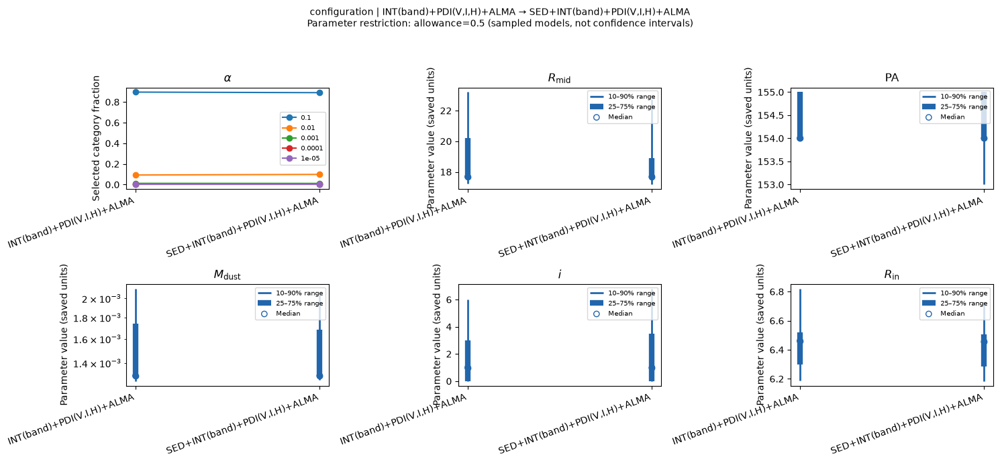

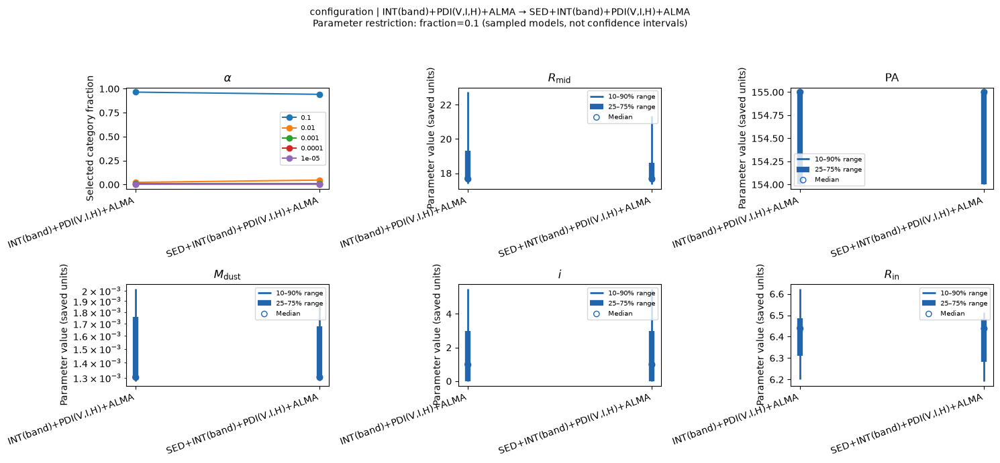

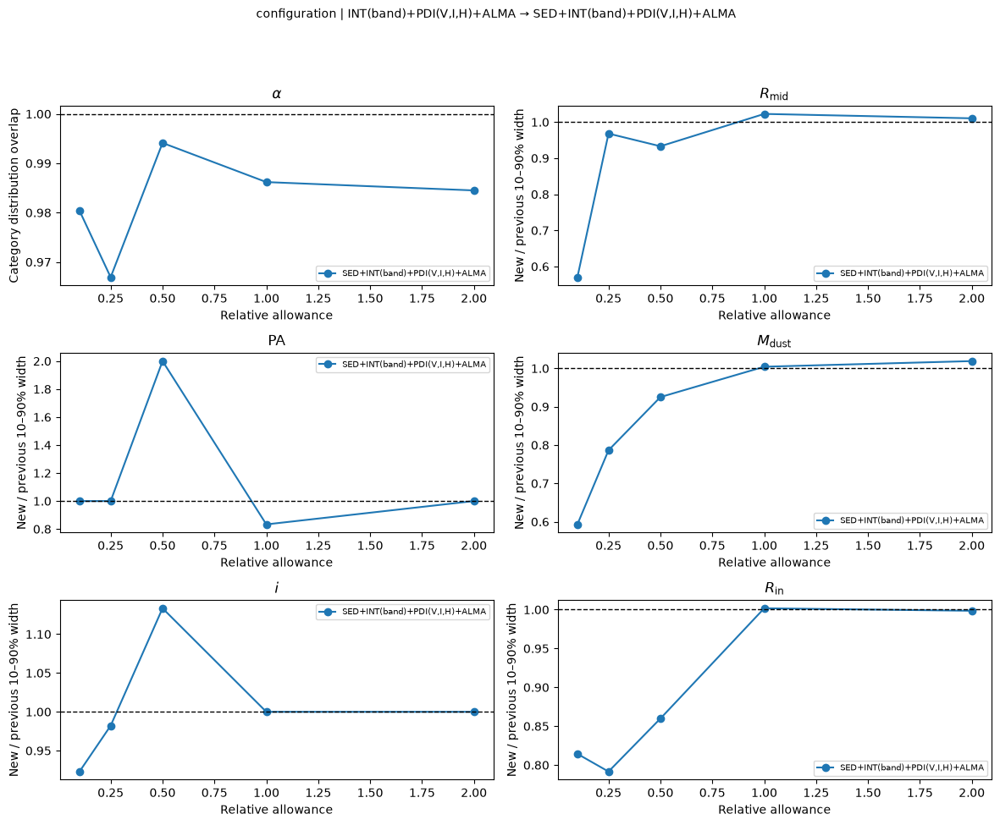

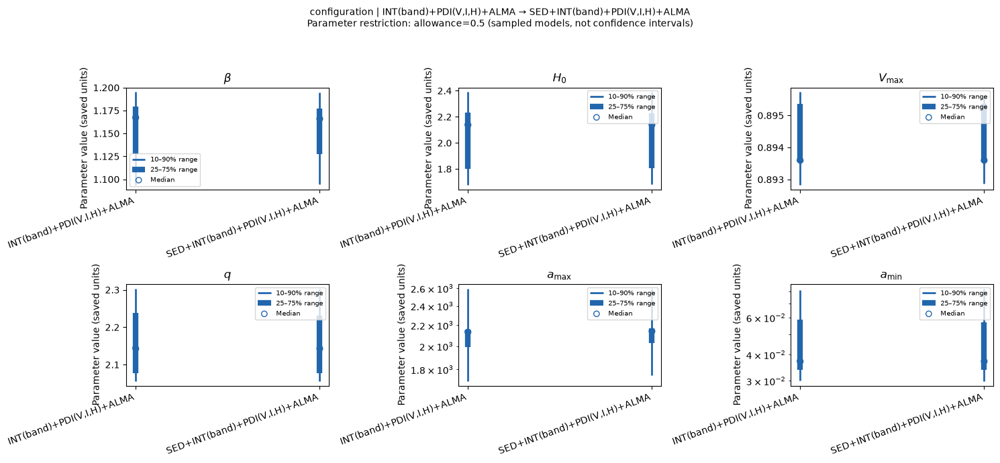

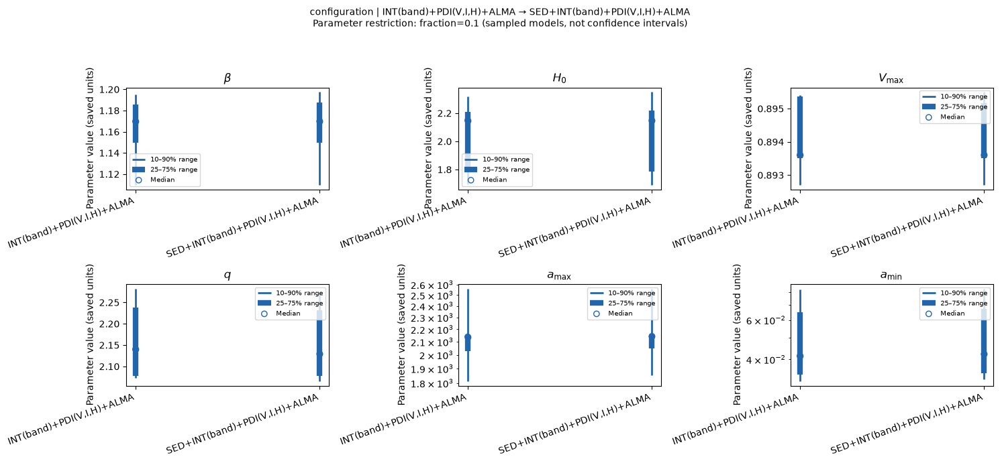

...

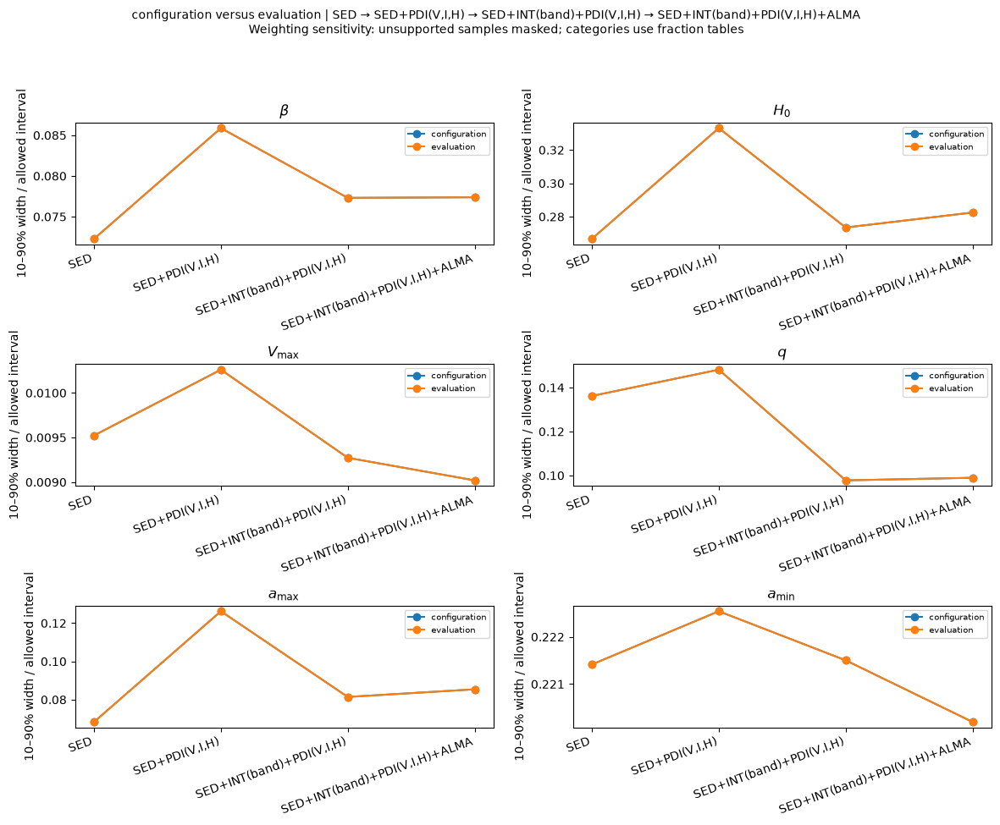

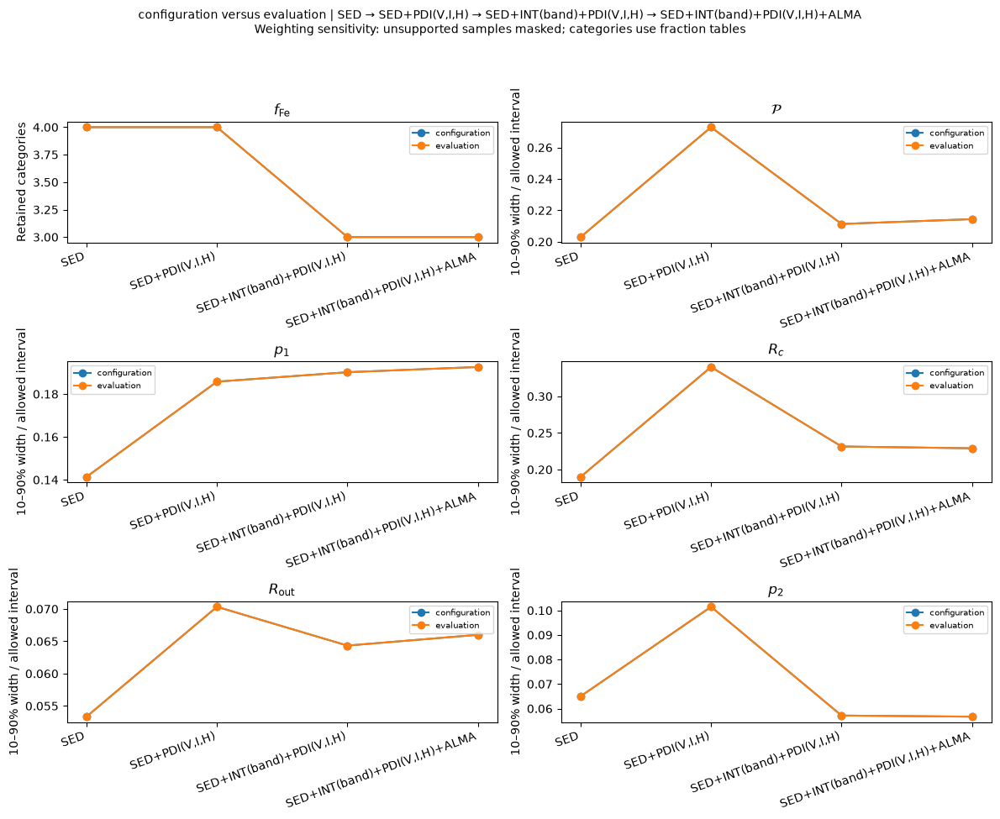

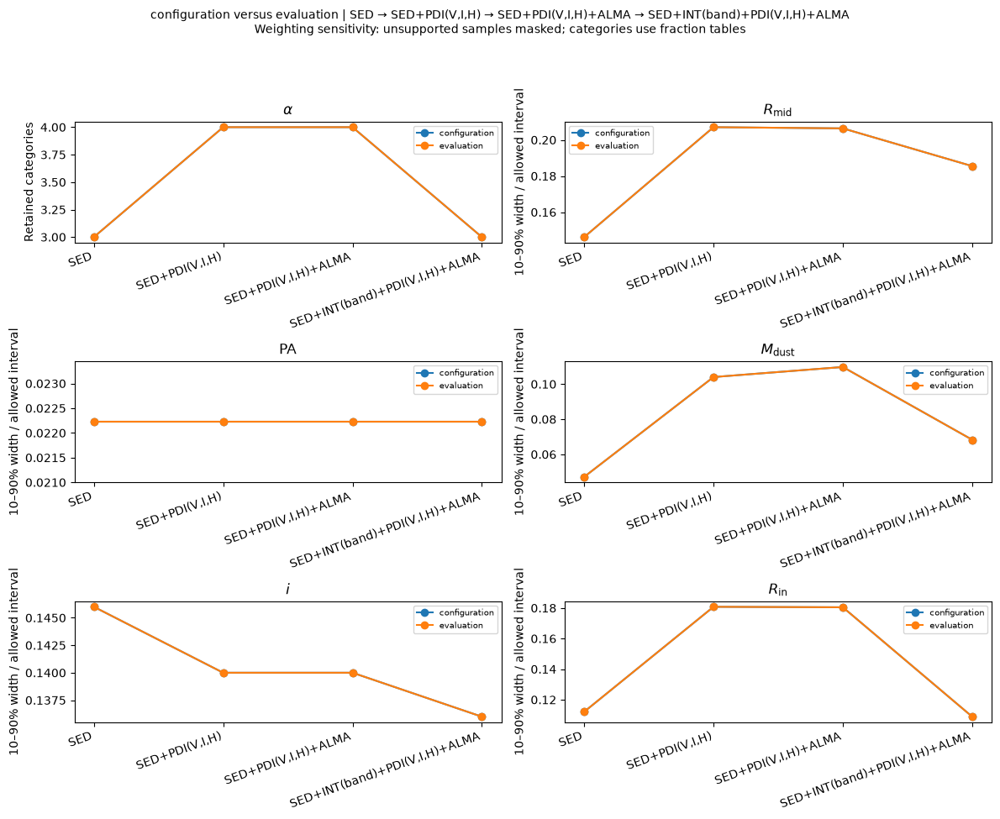

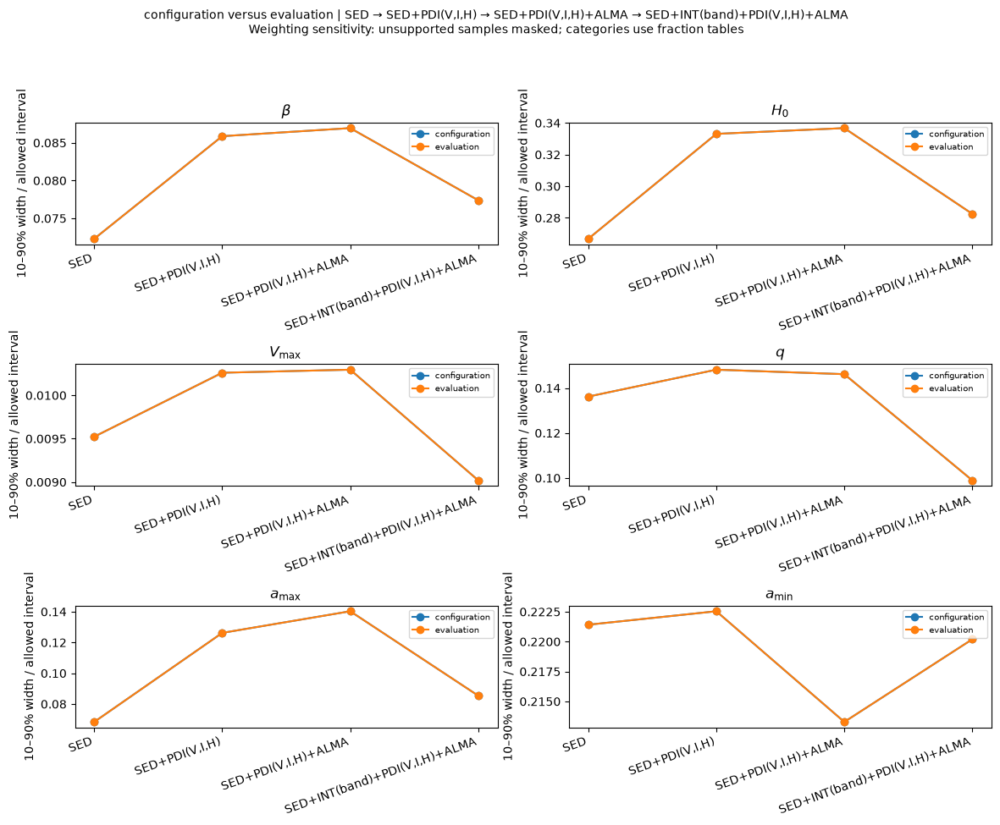

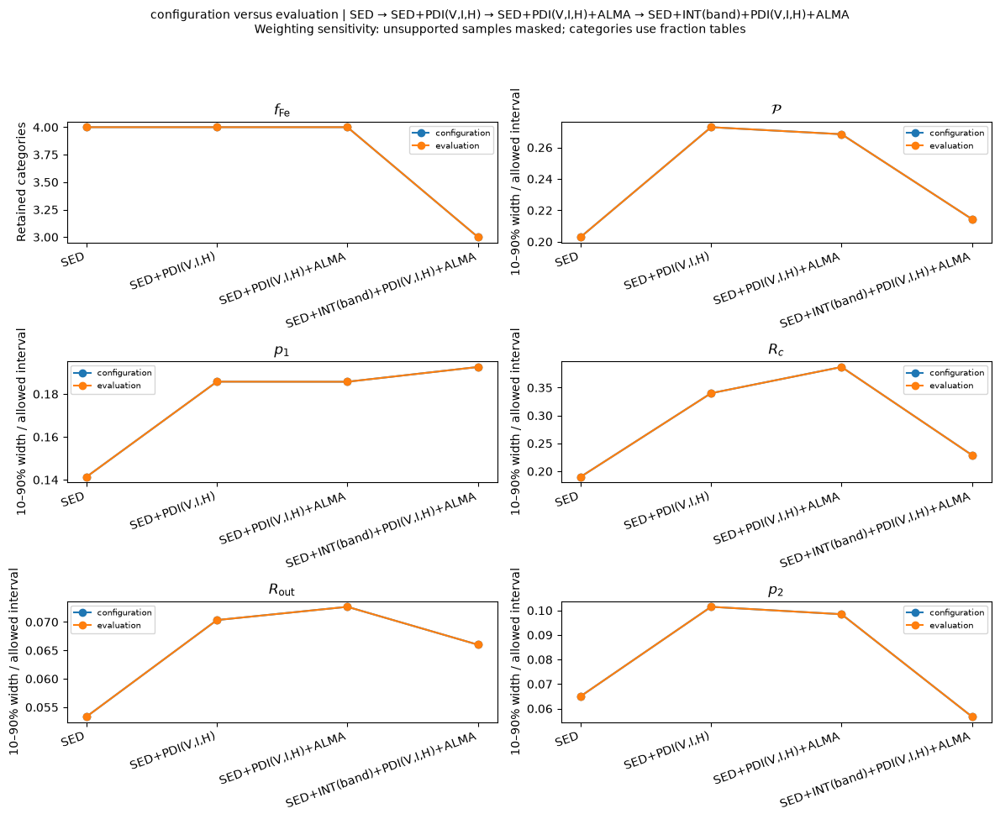

In [12]:
for weighting in plot_weightings:
    for sequence_index, sequence_name in enumerate(SEQUENCES, start=1):
        PLOT_CONTEXT={'weighting':weighting,'sequence':sequence_name,'scope':'pooled'}
        data = metrics[(metrics.weighting==weighting) & (metrics.scope=='pooled') & (metrics.sequence==sequence_name)]
        delta = changes[(changes.weighting==weighting) & (changes.scope=='pooled') & (changes.sequence==sequence_name)]
        for first in range(0,len(PARAMETERS),PARAMETERS_PER_FIGURE):
            names = PARAMETERS[first:first+PARAMETERS_PER_FIGURE]
            suffix = f'{weighting}_sequence_{sequence_index:02d}_{first//PARAMETERS_PER_FIGURE+1:02d}'
            show('restriction_allowance_'+suffix,plot_restriction(data,names,'allowance',DISPLAY_ALLOWANCE))
            show('restriction_matched_fraction_'+suffix,plot_restriction(data,names,'fraction',DISPLAY_FRACTION))
            show('threshold_width_sensitivity_'+suffix,plot_sensitivity(delta,names))

for sequence_index,sequence_name in enumerate(SEQUENCES,1):
    PLOT_CONTEXT={'weighting':'configuration versus evaluation','sequence':sequence_name,'scope':'pooled'}
    data=metrics[(metrics.scope=='pooled')&(metrics.sequence==sequence_name)]
    for first in range(0,len(PARAMETERS),PARAMETERS_PER_FIGURE):
        show(f'weighting_comparison_{sequence_index:02d}_{first:03d}',
             plot_weighting_comparison(data,PARAMETERS[first:first+PARAMETERS_PER_FIGURE],
                                       'allowance',DISPLAY_ALLOWANCE))


## 5. Marginal distributions and joint parameter relationships

These answer different questions:

| Plot | Horizontal axis | Vertical axis | Why this form? |
|---|---|---|---|
| Numeric marginal histogram | One parameter (linear or log10 coordinates) | Fraction of selected valid values per shared bin | Shows where one numeric parameter is concentrated |
| Categorical marginal bars | Allowed category labels | Fraction selecting each category | Keeps discrete choices separate without implying interpolation |
| Joint scatter | First numeric parameter | Second numeric parameter | Shows trade-offs, curved ridges, clusters and bounds |

For this ConfigSpace, **alpha_viscosity, Vmax, iron volume fraction and porosity are discrete categorical choices**, even though their values are numbers. They therefore use bars, while dust mass and radii use histograms. This is driven by the saved ConfigSpace, not the number of models. The parameter-type audit above lists the exact treatment for every parameter. Numeric integer parameters such as inclination use numeric histograms.

Every marginal distribution sums to one over its valid values; it is not a likelihood or probability density per physical unit. All objectives share bin edges and coordinates, also used by the overlap metric. The dashed black histogram is the full common-pool reference. In joint plots black points are all candidates and coloured points are the selected subsets. Colour consistently identifies the observation subset within a sequence. Sample counts appear in legends. Selections from different objectives need not be nested and may overlap on the plot.

A numeric parameter's log10 display is a coordinate transformation only. Category bars have equally spaced slots even when their numeric values are unevenly spaced. No continuous behaviour between those categories is inferred. Joint scatters with categorical axes are omitted rather than assigned an arbitrary numerical order.


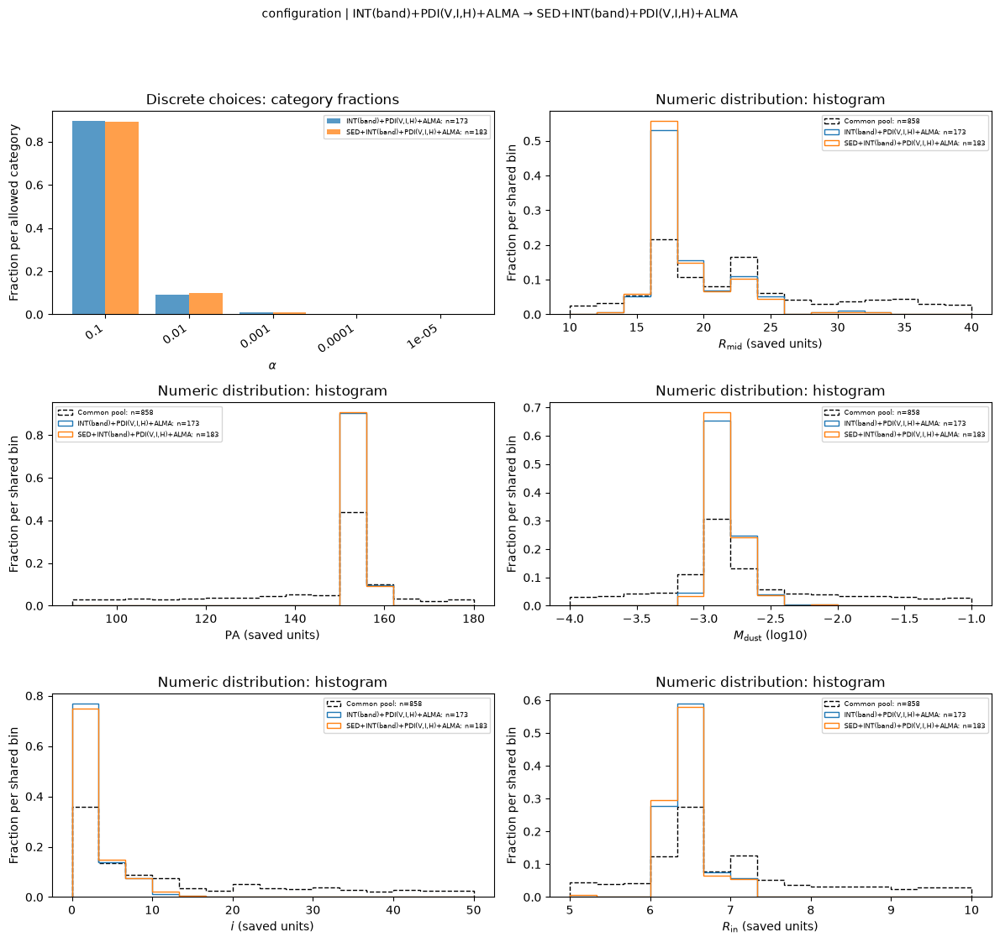

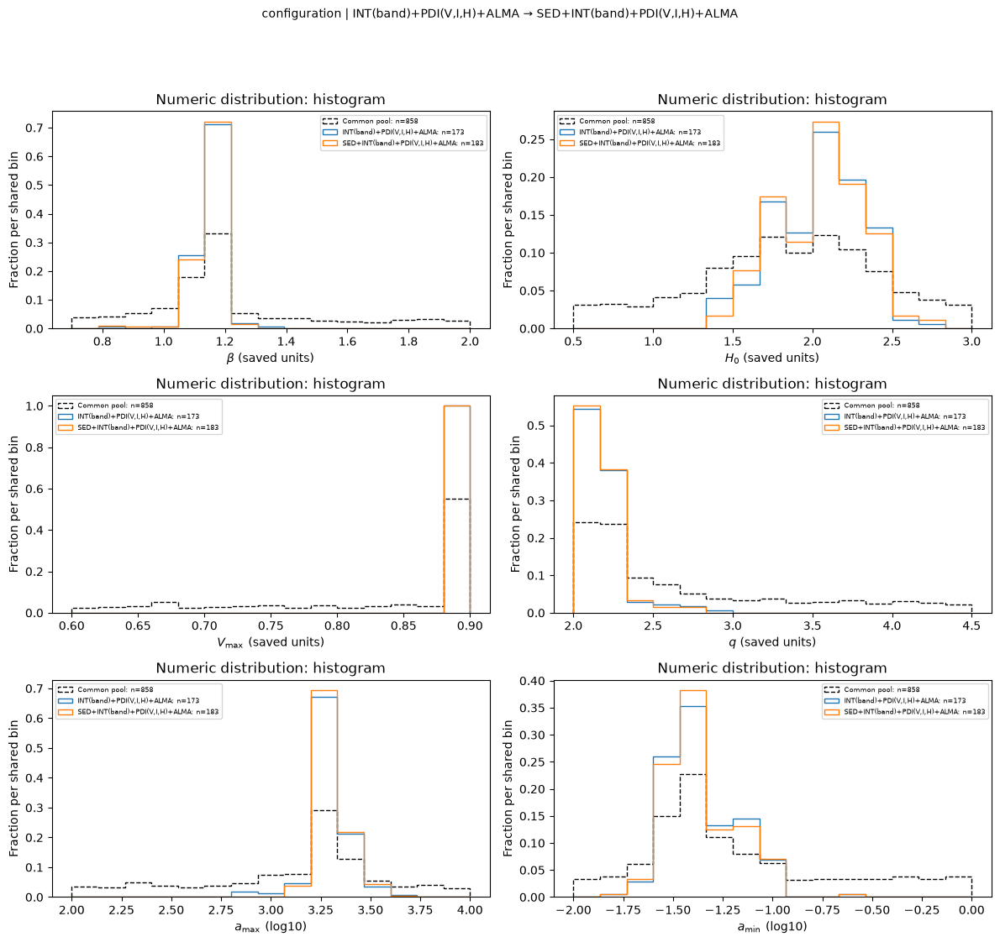

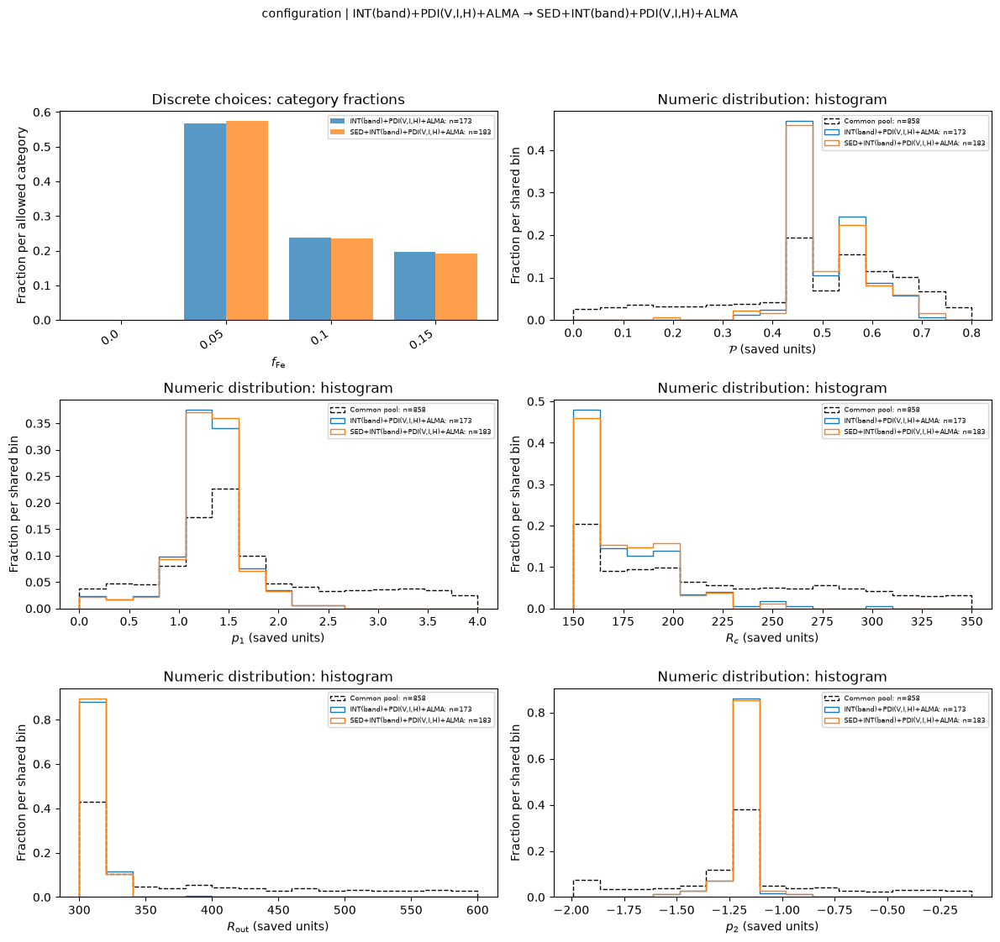

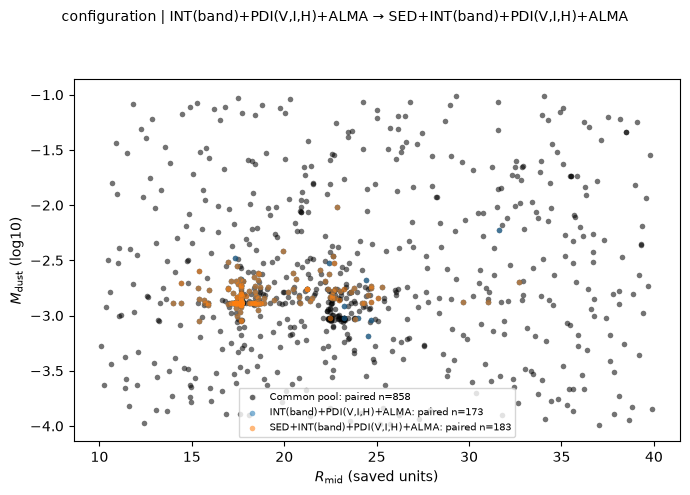

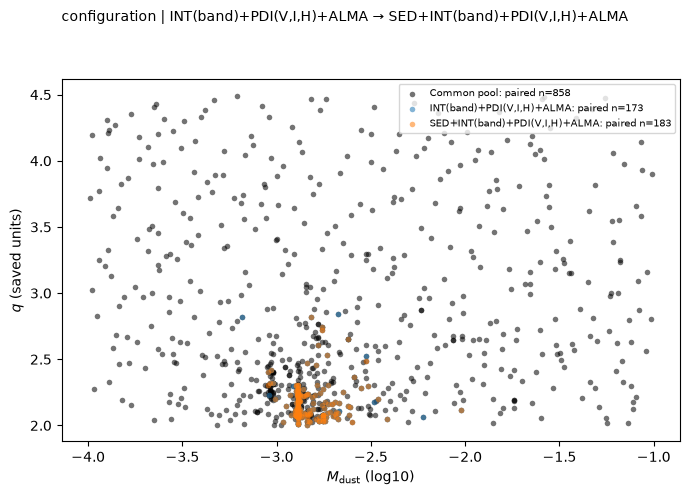

...

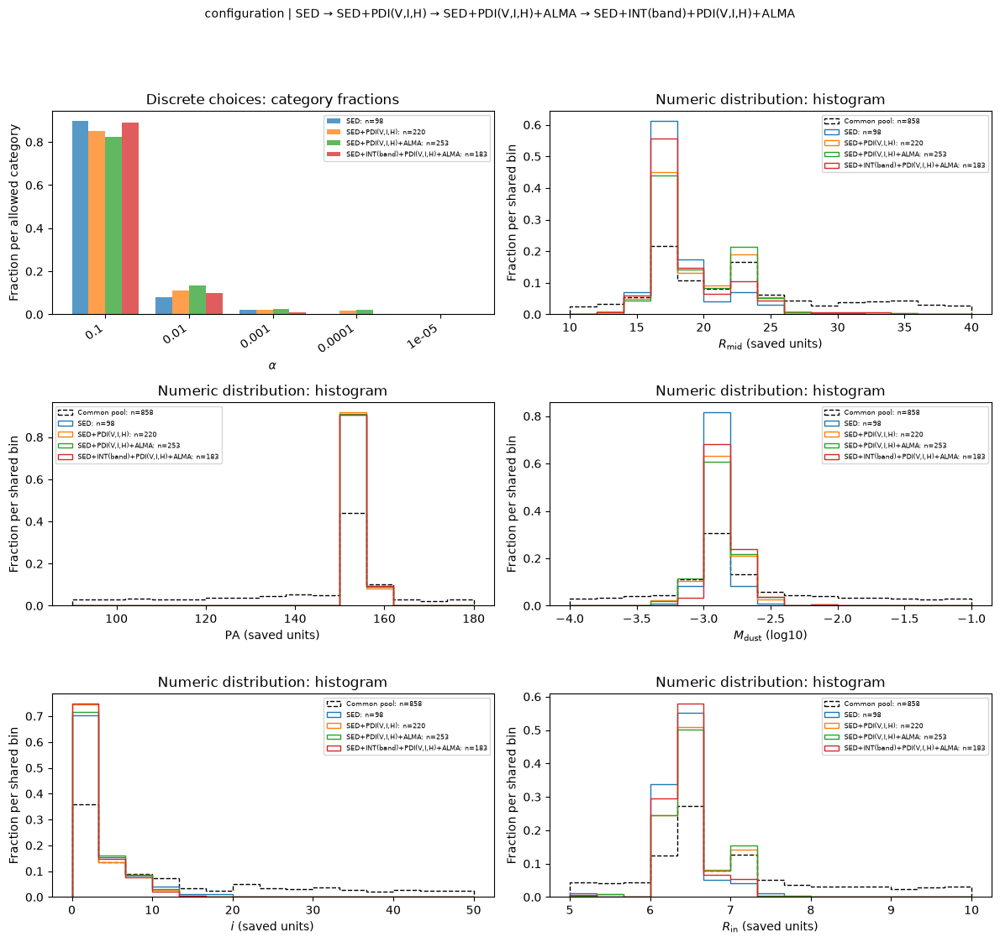

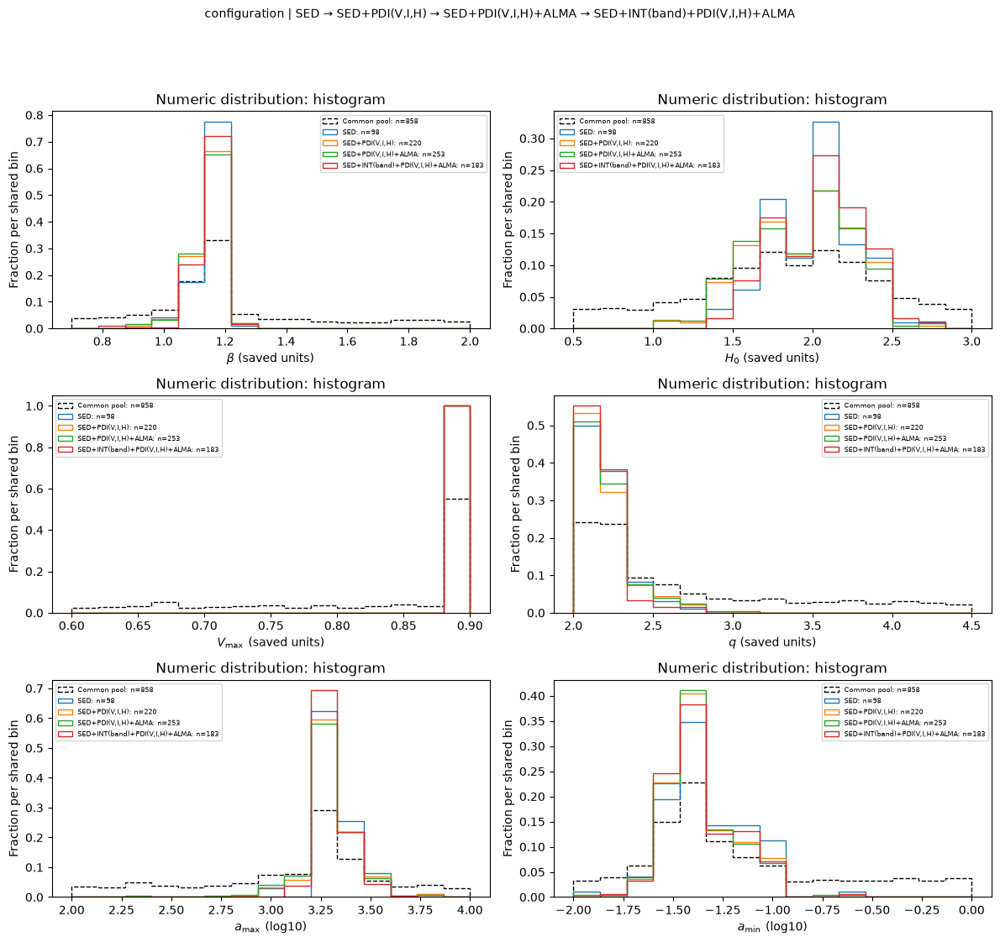

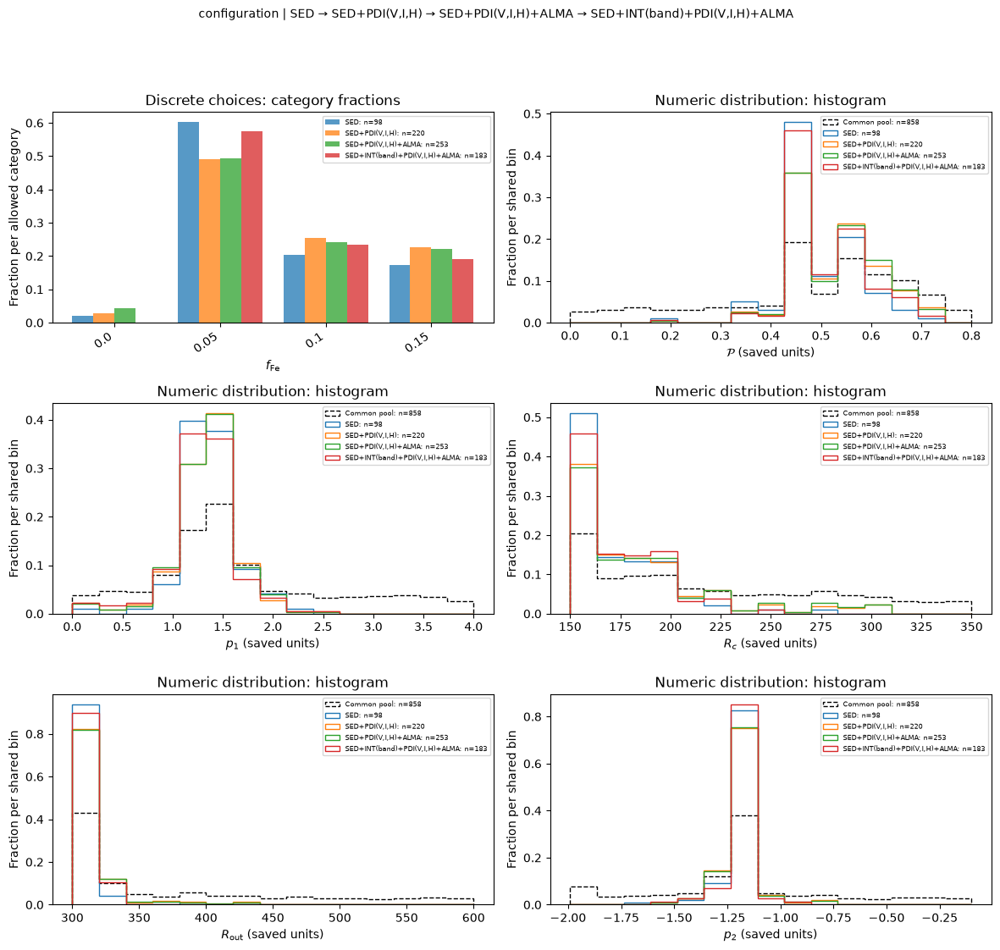

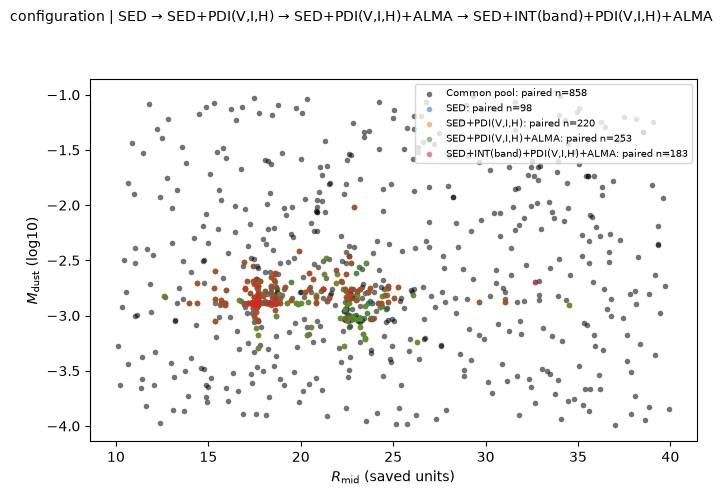

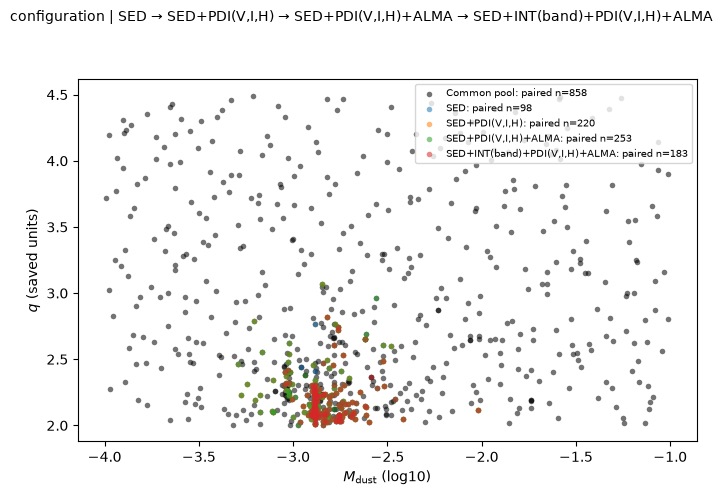

In [13]:
for weighting in plot_weightings:
    plotting_pool=pools[weighting]
    for sequence_index,(sequence_name,sequence) in enumerate(SEQUENCES.items(),1):
        PLOT_CONTEXT={'weighting':weighting,'sequence':sequence_name,'scope':'pooled',
                      'selection':'allowance','allowance':DISPLAY_ALLOWANCE}
        chosen={subset:select_models(plotting_pool,subset,'allowance',DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE)[0]
                for subset in sequence}
        for first in range(0,len(PARAMETERS),PARAMETERS_PER_FIGURE):
            names=PARAMETERS[first:first+PARAMETERS_PER_FIGURE]
            show(f'marginals_{weighting}_sequence_{sequence_index:02d}_{first:03d}',
                 plot_parameter_marginals(plotting_pool,chosen,names,parameter_references,MIN_MODELS))
        for x,y in JOINT_PAIRS:
            if x not in parameter_references or y not in parameter_references:
                print('Skipping unavailable pair:',x,y);continue
            figure=plot_joint_parameters(plotting_pool,chosen,x,y,parameter_references,POINT_SIZE,POINT_ALPHA)
            if figure is None:print('Joint scatter omitted for categorical axis:',x,y)
            show(f'joint_{weighting}_sequence_{sequence_index:02d}_{x}_{y}',figure)


## Parameter values versus observable scores

This is the direct link between a parameter value, fit quality and selection. One figure is produced per parameter for the chosen observation sequence and weighting view. All panels use the same candidates. PA uses its ordinary saved numeric values, as elsewhere in this notebook.

**Reading the figure:**
1. **Individual observable panels:** y is the original SED, summed interferometry, summed PDI or ALMA score. Black circles show every candidate; blue circles meet the allowance for that panel's individual observable. Blue membership is recalculated independently for each panel.
2. **Cumulative-objective panels:** y is the sum of the original contributions for each subset in the sequence. Blue circles meet that subset's allowance. Axes retain the actual score units, with independent y limits; numerical heights across different objectives are not equivalent statistical goodness of fit.
3. **Added-score panels:** y is the sum of newly added contributions, equal to expanded minus previous objective for the same candidate (up to floating-point roundoff). Blue circles identify models competitive under the **expanded objective**, not models selected solely by the added score. This distinguishes the new observational penalty from the resulting reselection.
4. **Distribution panel:** continuous parameters use ECDFs of the selected values for each cumulative objective; a dashed black ECDF shows the common pool. Steeper rises indicate concentration, horizontal shifts indicate movement. Categorical parameters use category-fraction bars instead; no continuous order is inferred.

All candidates use black circles and allowance-selected candidates use blue circles, with identical POINT_SIZE and POINT_ALPHA. Blue is drawn on top of the black reference; overlapping symbols can appear darker. Joint plots use the same size/opacity, with separate colours for each objective. Orange summaries show bin/category medians and green summaries show the configured low score quantile. For categories, whiskers span the low-to-high score quantiles and no line connects category values. Numeric bin counts appear along the panel base; category counts appear in tick labels. Sparse bins have no summary curve, although their original points remain visible.

A low-score valley suggests an observable favours that sampled parameter region. Vertical scatter reflects variations in other parameters and possibly simulation noise. Conflicting valleys suggest competing preferences. The lower quantile is a **sampled lower envelope**, not a reoptimised profile cost or likelihood: uneven coverage, narrow bins and other-parameter correlations affect it. Do not infer confidence intervals from these curves.

`PARAMETER_SCORE_SEQUENCE=None` chooses the longest compatible observed sequence. Choose another exact sequence name to examine a different addition path. Individual observable selections are diagnostic and independent of SCORE_OBSERVABLES in the pool lookup. Existing DISPLAY_ALLOWANCE and ABSOLUTE_ALLOWANCE control all competitive selections here. Both weighting views use the same parameter bins; configuration scores are repeat means and evaluation scores retain individual realisations.

Identical individual/cumulative objectives (for example SED as the baseline) share one panel. Added-score panels are retained even when their y values match an individual observable, because their blue selection refers to the expanded objective. Bin summaries use **all candidates in the bin**, not just blue points. Logarithmic score axes are the default to show large dynamic ranges; no scores are rescaled or reweighted. The figure and audit record when a panel falls back to linear because a score is nonpositive.


Parameter-score sequence: SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(band)+PDI(V,I,H)+ALMA


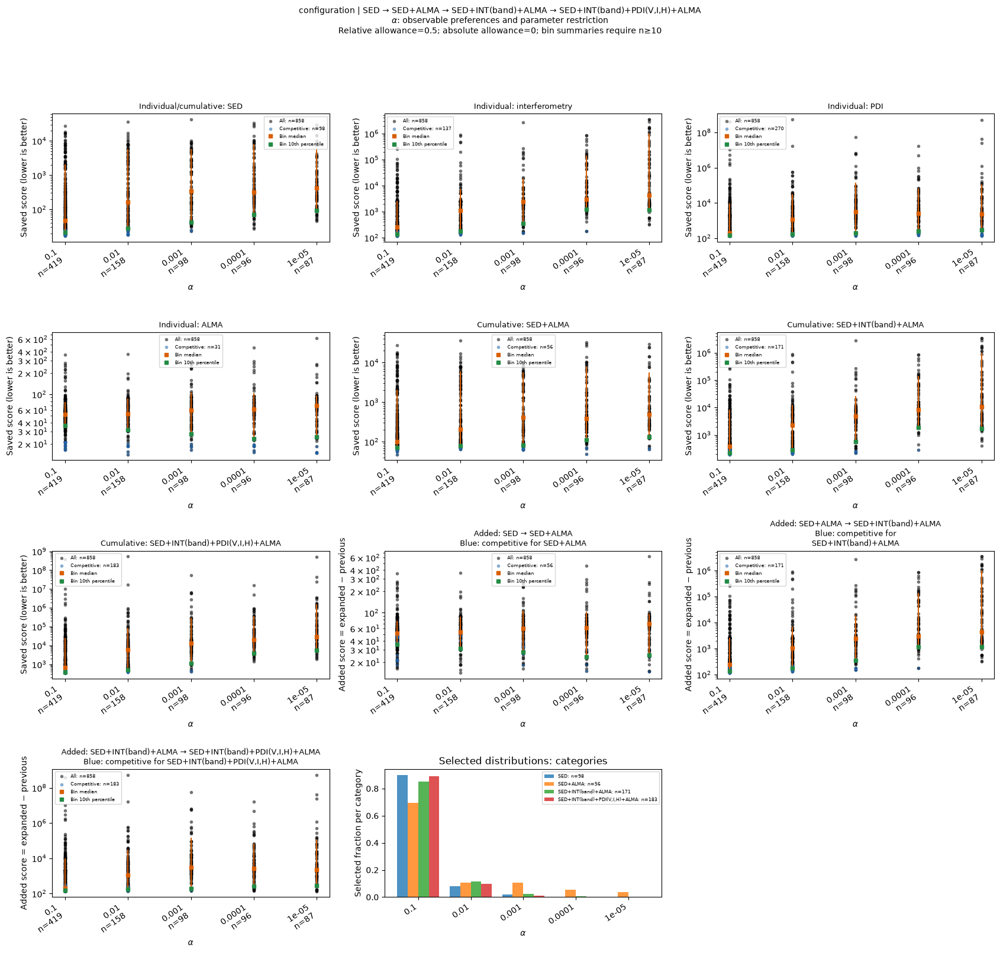

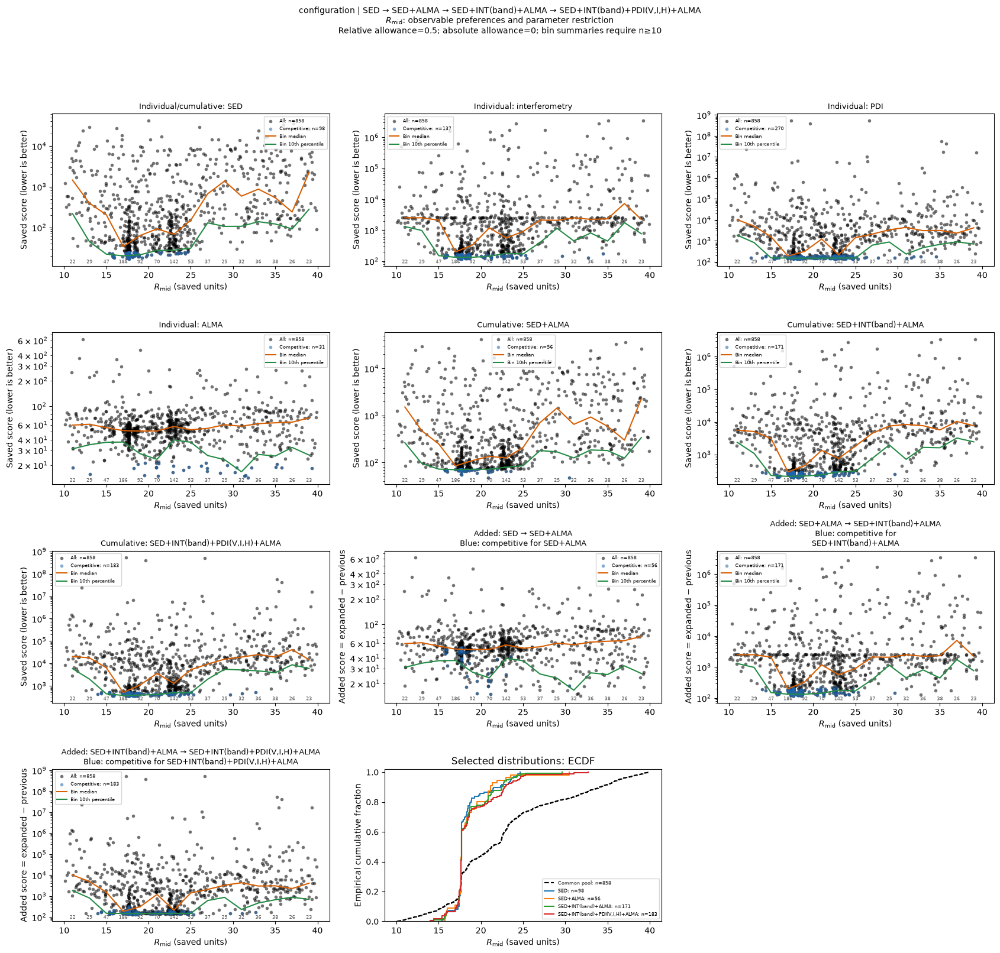

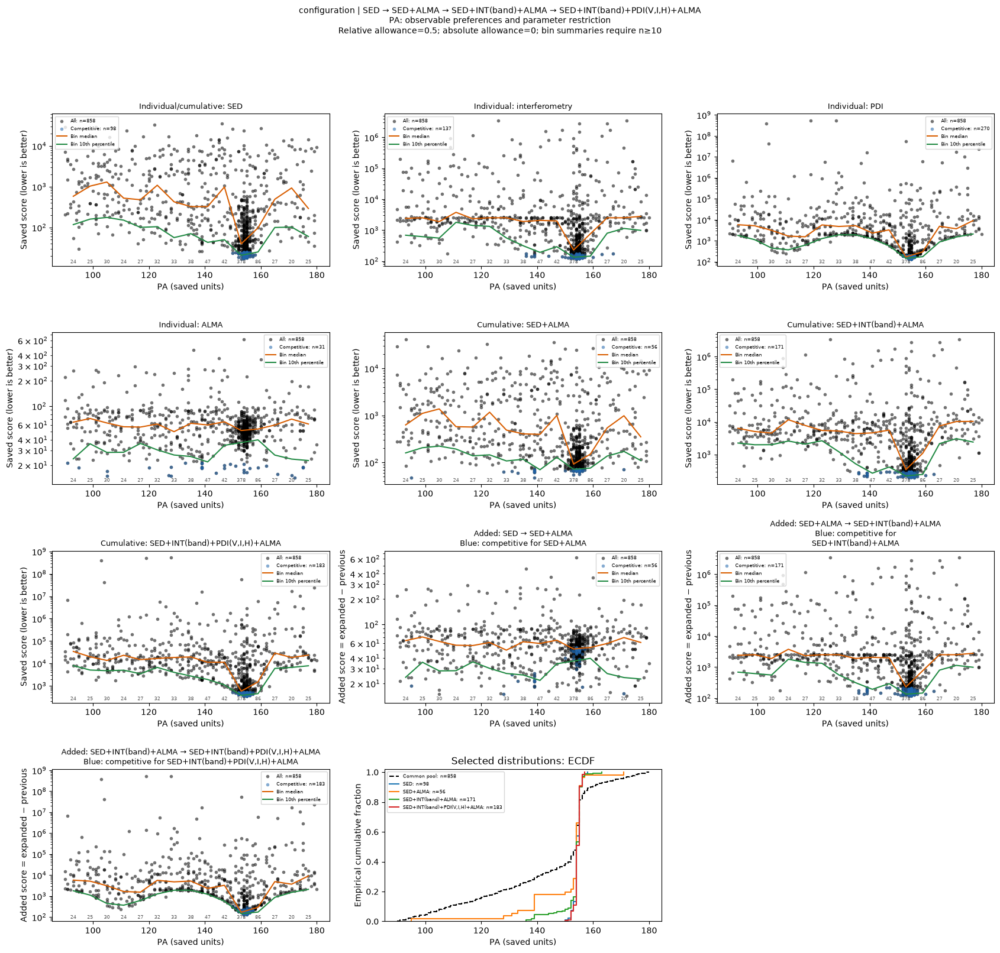

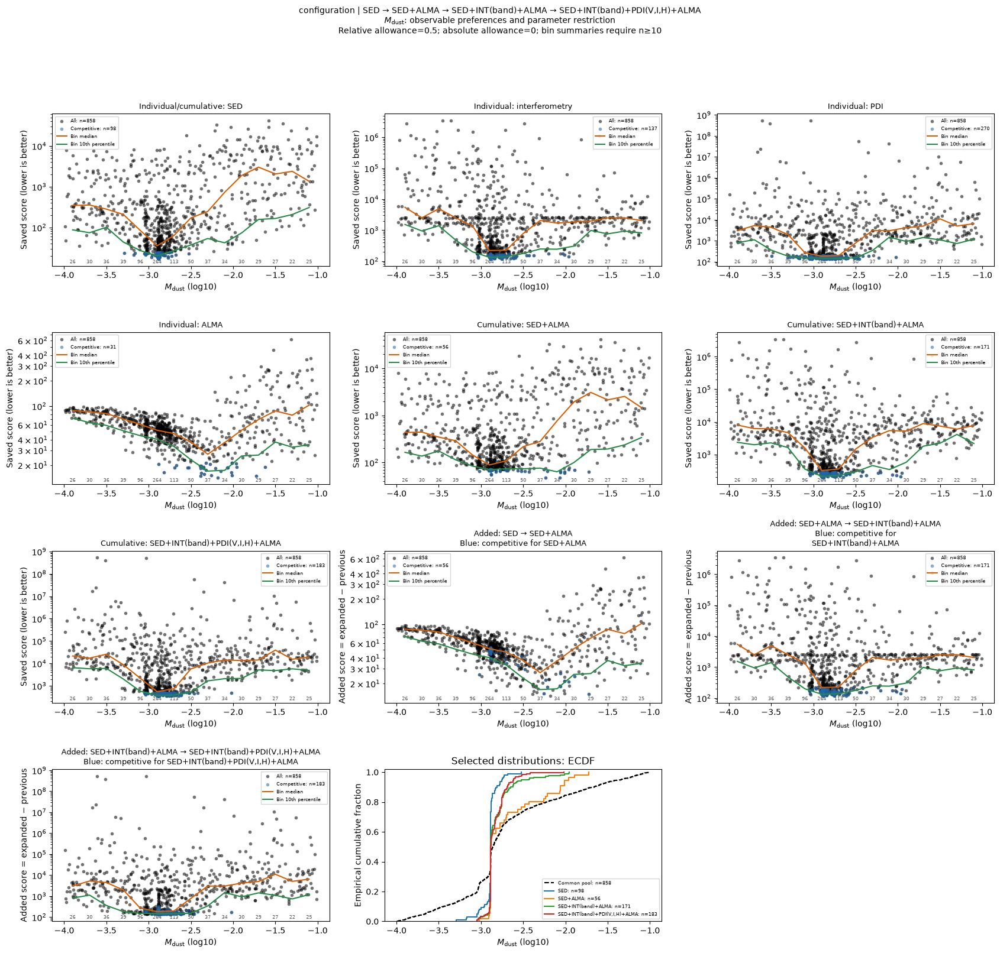

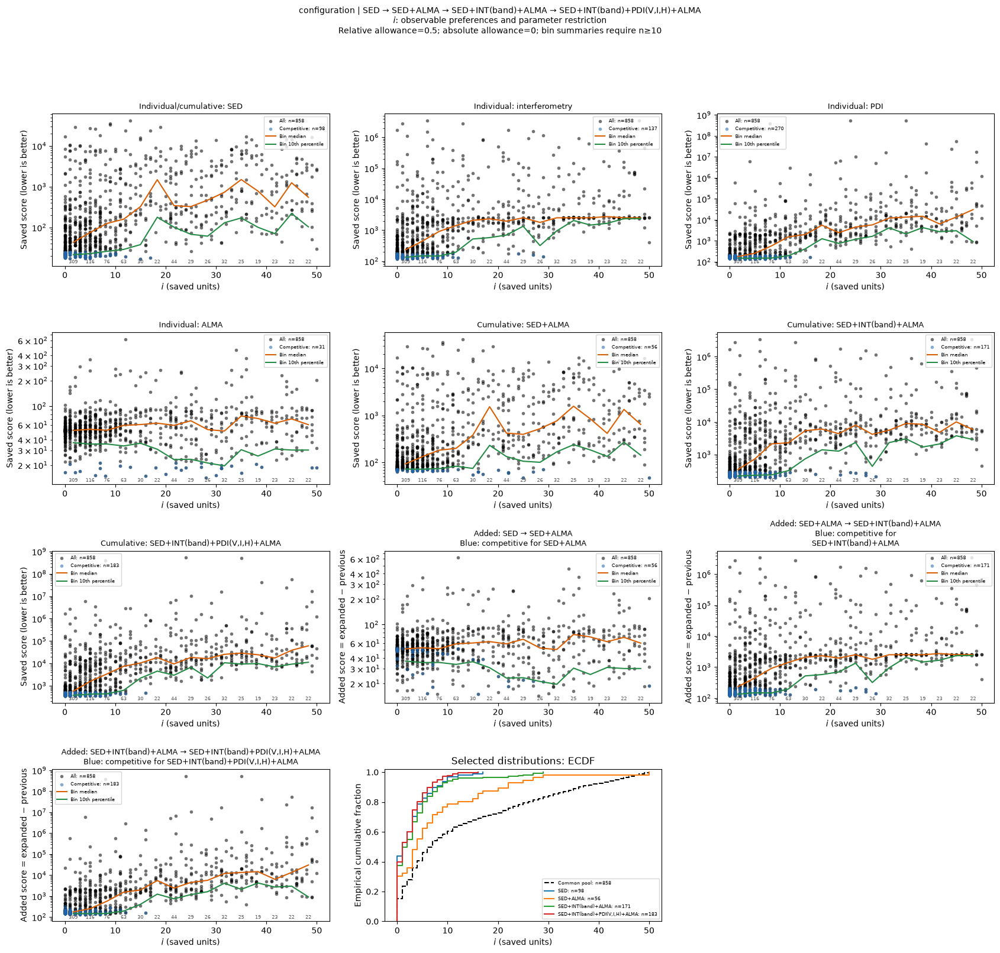

...

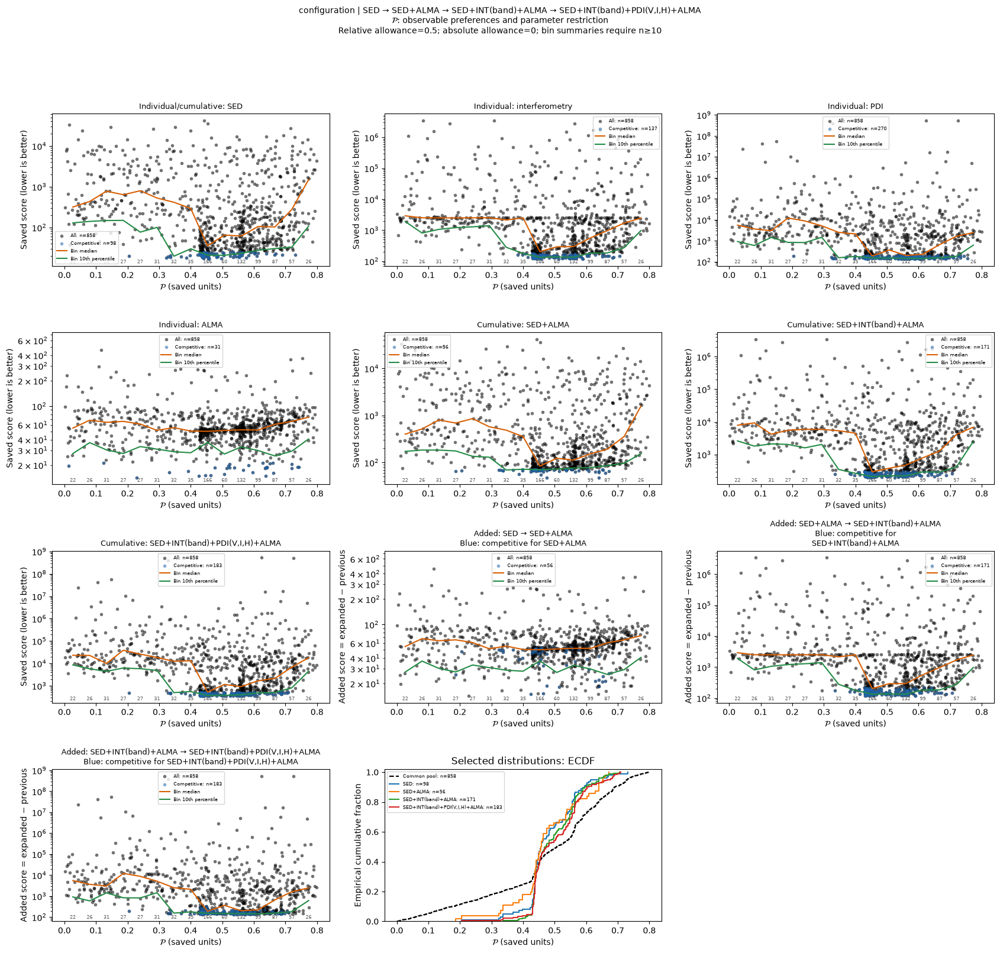

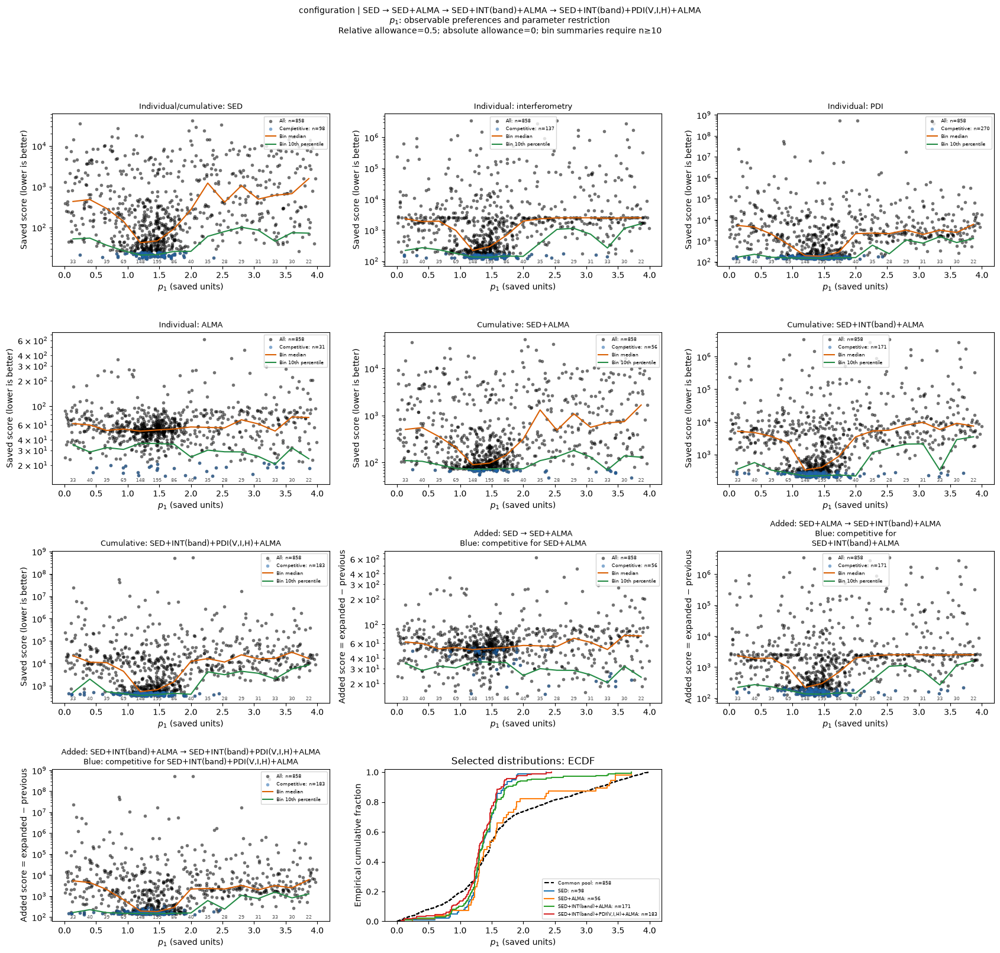

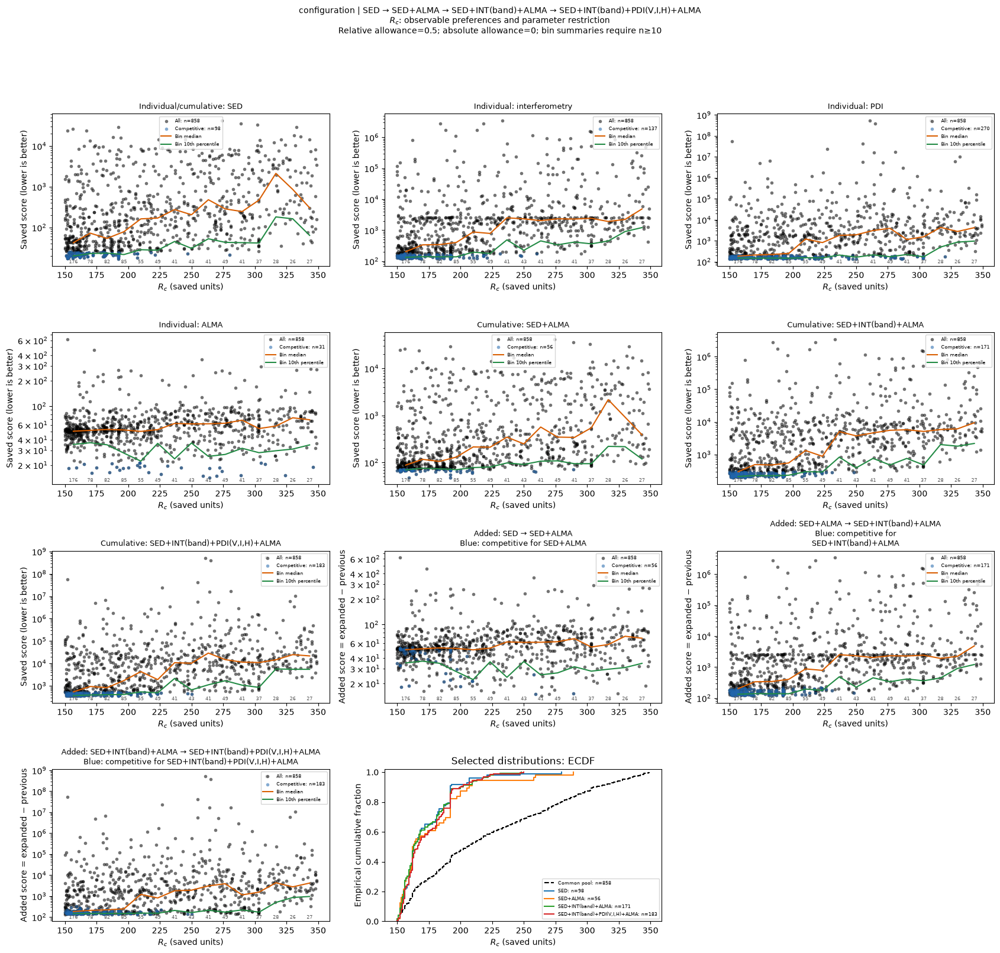

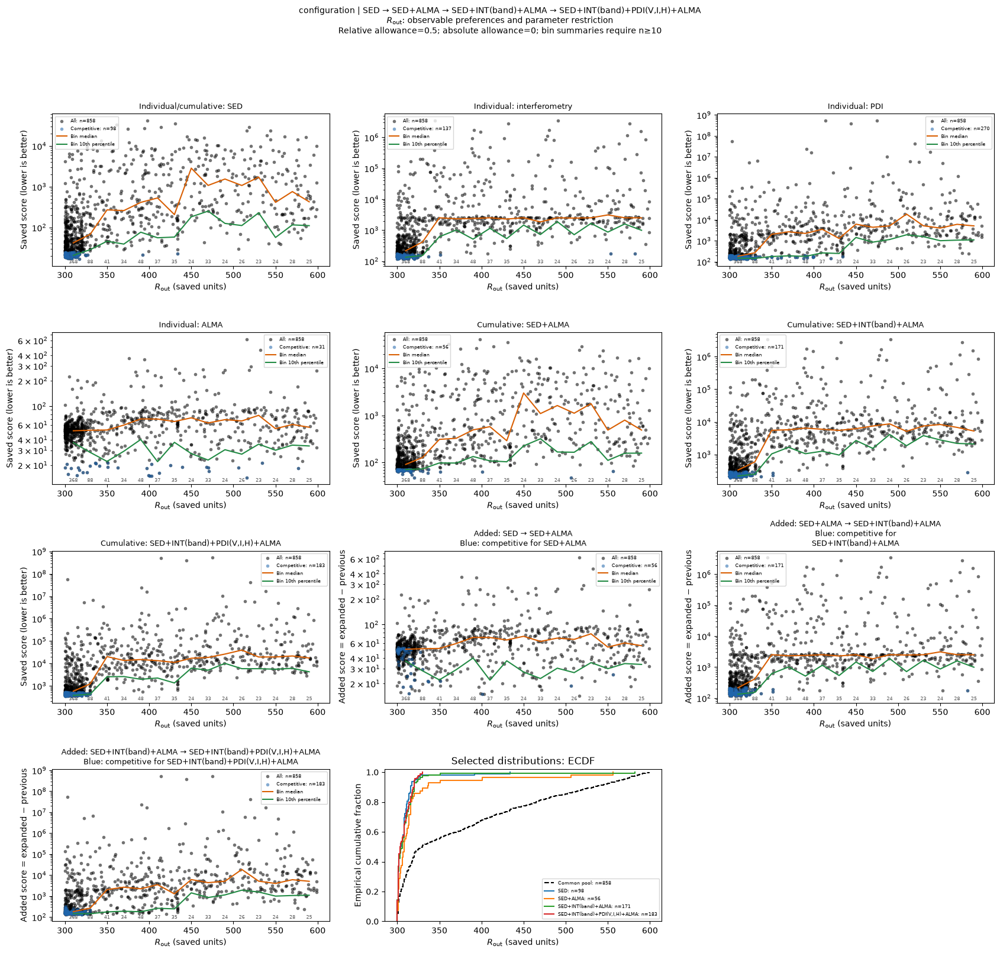

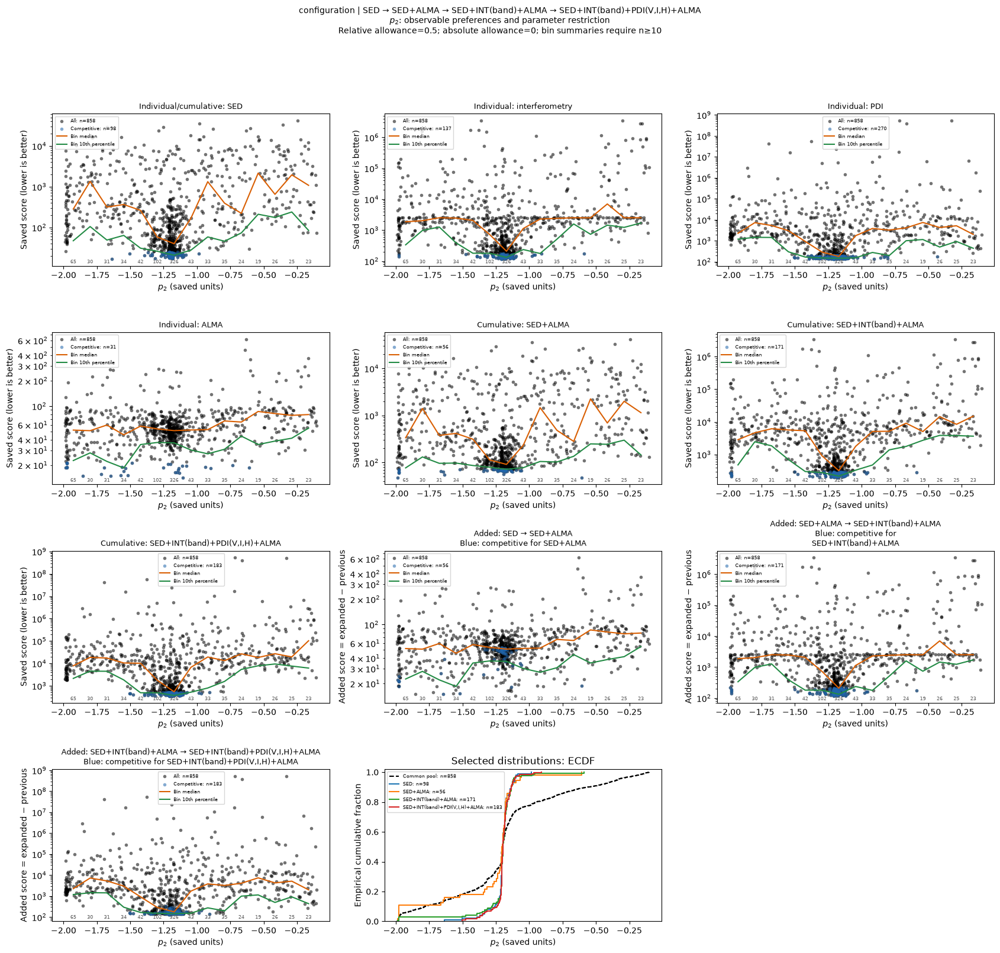

,parameter,panel,kind,objective,selection_objective,selection_cutoff,n_pool,n_valid_parameter,n_competitive,n_competitive_valid_parameter,score_scale,weighting,sequence,pool_group
0,alpha_viscosity,0,individual/cumulative,SED,SED,25.109948,858,858,98,98,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
1,alpha_viscosity,1,individual,interferometry,interferometry,175.080550,858,858,137,137,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
2,alpha_viscosity,2,individual,PDI,PDI,200.253496,858,858,270,270,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
3,alpha_viscosity,3,individual,ALMA,ALMA,21.347434,858,858,31,31,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
4,alpha_viscosity,4,cumulative,SED+ALMA,SED+ALMA,71.901560,858,858,56,56,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,zone_2_surface_density_exp,5,cumulative,SED+INT(band)+ALMA,SED+INT(band)+ALMA,293.956517,858,858,171,171,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
176,zone_2_surface_density_exp,6,cumulative,"SED+INT(band)+PDI(V,I,H)+ALMA","SED+INT(band)+PDI(V,I,H)+ALMA",525.845066,858,858,183,183,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
177,zone_2_surface_density_exp,7,added,SED → SED+ALMA,SED+ALMA,71.901560,858,858,56,56,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936
178,zone_2_surface_density_exp,8,added,SED+ALMA → SED+INT(band)+ALMA,SED+INT(band)+ALMA,293.956517,858,858,171,171,log,configuration,SED → SED+ALMA → SED+INT(band)+ALMA → SED+INT(...,53b5191ef936


In [14]:
parameter_score_sequence_name = (PARAMETER_SCORE_SEQUENCE if PARAMETER_SCORE_SEQUENCE is not None
                                 else max(SEQUENCES,key=lambda key:len(SEQUENCES[key])))
if parameter_score_sequence_name not in SEQUENCES:
    raise ValueError('PARAMETER_SCORE_SEQUENCE must be one of the displayed compatible sequence names.')
parameter_score_names = PARAMETERS if PARAMETER_SCORE_PARAMETERS is None else list(dict.fromkeys(PARAMETER_SCORE_PARAMETERS))
if any(name not in parameter_references for name in parameter_score_names):
    raise ValueError('PARAMETER_SCORE_PARAMETERS must be included in PARAMETERS.')
print('Parameter-score sequence:',parameter_score_sequence_name)
score_panel_tables,score_bin_tables=[],[]
for weighting in plot_weightings:
    for parameter_index,name in enumerate(parameter_score_names,1):
        PLOT_CONTEXT={'weighting':weighting,'sequence':parameter_score_sequence_name,'scope':'pooled',
                      'selection':'allowance','allowance':DISPLAY_ALLOWANCE,'parameter':name}
        fig,panel_audit,bin_audit=parameter_score_diagnostic(
            pools[weighting],name,parameter_references[name],SEQUENCES[parameter_score_sequence_name],
            PARAMETER_SCORE_OBSERVABLES,DISPLAY_ALLOWANCE,ABSOLUTE_ALLOWANCE,
            PARAMETER_SCORE_MIN_BIN_MODELS,PARAMETER_SCORE_LOWER_QUANTILE,PARAMETER_SCORE_SCALE,
            point_size=POINT_SIZE,point_alpha=POINT_ALPHA)
        for table,collection in [(panel_audit,score_panel_tables),(bin_audit,score_bin_tables)]:
            table['weighting']=weighting;table['sequence']=parameter_score_sequence_name
            table['pool_group']=selected_group;collection.append(table)
        show(f'parameter_scores_{weighting}_{parameter_index:02d}_{name}',fig)
parameter_score_panels=pd.concat(score_panel_tables,ignore_index=True) if score_panel_tables else pd.DataFrame()
parameter_score_bins=pd.concat(score_bin_tables,ignore_index=True) if score_bin_tables else pd.DataFrame()
display(parameter_score_panels)


## 6. Reproducibility and search stability

The per-history tables repeat the full observation-addition experiment on the candidates originating in each history. Agreement across histories is useful only when they represent independent optimiser seeds under comparable original objectives and physical settings. Different source search objectives are not interchangeable seed replicates. A single history cannot establish reproducibility; trial seeds are not independent optimiser histories.

The prefix check below uses the first 50%, 75% and 100% of each history's chronological fully scored evaluations, then reconstructs both weighting views within each prefix. It reports whether preferred regions keep moving as the saved search grows. It is descriptive: adaptive sampling, repeat noise and missing historical evaluations can affect it. It does not replace additional independent searches or repeated simulations of leading configurations.


In [15]:
history_comparison = metrics[(metrics.scope!='pooled') & (metrics['mode']=='allowance')
                             & np.isclose(metrics.level,DISPLAY_ALLOWANCE)].copy()
display(history_comparison.reindex(columns=['weighting','scope','sequence','subset','parameter','n_pool','n_selected',
    'supported','kind','median_in_parameter_units','width_fraction_of_bounds','fraction_near_boundary',
    'retained_categories','category_fractions']))
if selected.history.nunique()<2:
    print('Only one compatible source history: independent-history agreement cannot be assessed.')
stability_parts=[]
for history,rows in selected.groupby('history',sort=False):
    ordered=rows.sort_values(['endtime','record_index'],na_position='last')
    for fraction in [.5,.75,1.]:
        prefix=ordered.iloc[:max(1,math.ceil(len(ordered)*fraction))]
        prefix_pools,_=convergence_views(prefix)
        for weighting,candidates in prefix_pools.items():
            for sequence_name,sequence in SEQUENCES.items():
                table,_,_=restriction_analysis(candidates,definitions,sequence,PARAMETERS,
                    [DISPLAY_ALLOWANCE],[],ABSOLUTE_ALLOWANCE,MIN_MODELS,PERIODS,HISTOGRAM_BINS, references=parameter_references)
                table['weighting']=weighting
                table['history']=history;table['sequence']=sequence_name;table['evaluation_prefix_fraction']=fraction
                stability_parts.append(table)
search_stability=pd.concat(stability_parts,ignore_index=True)
display(search_stability.reindex(columns=['weighting','history','sequence','evaluation_prefix_fraction','subset','parameter',
    'n_pool','n_selected','supported','median_in_parameter_units','width_fraction_of_bounds','fraction_near_boundary']))


,weighting,scope,sequence,subset,parameter,n_pool,n_selected,supported,kind,median_in_parameter_units,width_fraction_of_bounds,fraction_near_boundary,retained_categories,category_fractions
7560,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",alpha_viscosity,858,173,True,categorical,NaN,NaN,NaN,3.0,"{""0.1"": 0.8959537572254336, ""0.01"": 0.09248554..."
7561,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_Rmid,858,173,True,linear,17.682574,0.198804,0.000000,NaN,NaN
7562,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_pa,858,173,True,linear,154.000000,0.011111,0.000000,NaN,NaN
7563,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",disk_total_dust_mass,858,173,True,log10,0.001305,0.073839,0.000000,NaN,NaN
7564,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...","INT(band)+PDI(V,I,H)+ALMA",inclination,858,173,True,linear,1.000000,0.120000,0.554913,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14611,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_species_1_porosity,858,183,True,linear,0.475411,0.214383,0.000000,NaN,NaN
14612,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_surface_density_exp,858,183,True,linear,1.304437,0.192590,0.005464,NaN,NaN
14613,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rc,858,183,True,linear,166.000000,0.229000,0.120219,NaN,NaN
14614,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...","SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rout,858,183,True,linear,303.000000,0.066000,0.562842,NaN,NaN


Only one compatible source history: independent-history agreement cannot be assessed.


,weighting,history,sequence,evaluation_prefix_fraction,subset,parameter,n_pool,n_selected,supported,median_in_parameter_units,width_fraction_of_bounds,fraction_near_boundary
0,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",0.5,"INT(band)+PDI(V,I,H)+ALMA",alpha_viscosity,429,11,False,NaN,NaN,NaN
1,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",0.5,"INT(band)+PDI(V,I,H)+ALMA",disk_Rmid,429,11,False,22.598662,0.051083,0.000000
2,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",0.5,"INT(band)+PDI(V,I,H)+ALMA",disk_pa,429,11,False,155.000000,0.011111,0.000000
3,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",0.5,"INT(band)+PDI(V,I,H)+ALMA",disk_total_dust_mass,429,11,False,0.001226,0.138490,0.000000
4,configuration,seed1/sed_all_pdi_unres_corr [seed 358239],"INT(band)+PDI(V,I,H)+ALMA → SED+INT(band)+PDI(...",0.5,"INT(band)+PDI(V,I,H)+ALMA",inclination,429,11,False,4.000000,0.200000,0.272727
...,...,...,...,...,...,...,...,...,...,...,...,...
2803,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",1.0,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_species_1_porosity,858,183,True,0.475411,0.214383,0.000000
2804,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",1.0,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_1_surface_density_exp,858,183,True,1.304437,0.192590,0.005464
2805,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",1.0,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rc,858,183,True,166.000000,0.229000,0.120219
2806,evaluation,seed1/sed_all_pdi_unres_corr [seed 358239],"SED → SED+PDI(V,I,H) → SED+PDI(V,I,H)+ALMA → S...",1.0,"SED+INT(band)+PDI(V,I,H)+ALMA",zone_2_Rout,858,183,True,303.000000,0.066000,0.562842


## 7. Save results and interpretation

Report a parameter as increasingly restricted only when the selected region narrows robustly across allowances, remains supported by sufficient models, is not merely pinned to a bound, and survives the matched-fraction control. Check joint plots for remaining trade-offs. A shifted region can indicate new observational preference or a compromise between incompatible constraints, rather than refinement of an earlier solution.

No p-values, posterior probabilities or confidence levels are inferred from this optimiser-selected pool. Missing alternative solutions remain a coverage limitation. Use the recorded history hashes to identify the saved-data snapshot.


In [16]:
tables={'parameter_values_summary':parameter_values_summary,
        'parameter_score_panels':parameter_score_panels,
        'parameter_score_bins':parameter_score_bins,
        'parameter_type_audit':parameter_type_audit,'sequence_pool_audit':sequence_pool_audit,
        'figure_index':pd.DataFrame(figure_records),
        'repeat_variability':repeat_variability,
        'weighting_comparison':weighting_comparison.reset_index().pipe(
            lambda frame: frame.set_axis(['_'.join(str(v) for v in col if v) for col in frame.columns],axis=1)),
        'configuration_candidates':pools['configuration'],'evaluation_candidates':pools['evaluation'],
        'model_identifiers':evaluations[['model_id','evaluation_id','history','config_id','budget','parameter_hash']],
        'pool_identifiers':evaluations[['pool_id','comparison_key','history']].drop_duplicates(),
        'pool_score_summary':score_summary,'pool_score_evaluations':score_evaluations,
        'pool_score_coverage':score_coverage,
        'fidelity_stages':fidelity_stage_table,'sequence_provenance':sequence_provenance,
        'inventory':inventory,'pool_groups':groups.reset_index(),
        'subset_selection_counts':selections,'parameter_metrics':metrics,'observation_addition_changes':changes,
        'parameter_summary':parameter_summary,'per_history_comparison':history_comparison,
        'search_prefix_stability':search_stability}
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    for name,table in tables.items():table.to_csv(OUTPUT_DIR/(name+'.csv'),index=False)
    for name,figure in figures.items():figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=160,bbox_inches='tight')
    settings=dict(run_folders={k:str(v) for k,v in RUN_FOLDERS.items()},pool_group=selected_group,
        sequence_source=SEQUENCE_SOURCE,sequences=SEQUENCES,parameters=PARAMETERS,
        score_observables=SCORE_OBSERVABLES,score_parameter_filters=SCORE_PARAMETER_FILTERS,
        score_model_ids=SCORE_MODEL_IDS,score_final_only=SCORE_FINAL_ONLY,relative_allowances=RELATIVE_ALLOWANCES,
        absolute_allowance=ABSOLUTE_ALLOWANCE,matched_fractions=MATCHED_FRACTIONS,
        display_allowance=DISPLAY_ALLOWANCE,display_fraction=DISPLAY_FRACTION,min_models=MIN_MODELS,
        histogram_bins=HISTOGRAM_BINS,periods=PERIODS,joint_pairs=JOINT_PAIRS,
        point_size=POINT_SIZE,point_alpha=POINT_ALPHA,
        parameter_score=dict(sequence=parameter_score_sequence_name,parameters=parameter_score_names,
            observables=PARAMETER_SCORE_OBSERVABLES,scale=PARAMETER_SCORE_SCALE,
            min_bin_models=PARAMETER_SCORE_MIN_BIN_MODELS,lower_quantile=PARAMETER_SCORE_LOWER_QUANTILE),
        primary_weighting=PRIMARY_WEIGHTING,skip_identical_weighting_plots=SKIP_IDENTICAL_WEIGHTING_PLOTS,
        parameter_references=parameter_references,plot_both_weightings=PLOT_BOTH_WEIGHTINGS,
        repeat_handling='Original evaluations remain unique; configuration view averages complete vectors only within compatible configuration/budget/instance groups')
    (OUTPUT_DIR/'settings.json').write_text(json.dumps(settings,indent=2))
    print('Saved to',OUTPUT_DIR)
else:
    print('Exports disabled. Tables and figures remain available in memory.')


Exports disabled. Tables and figures remain available in memory.


## Critical review: what this analysis can establish

**Implemented corrections:** stage discovery no longer changes the shared objective dictionary and correctly handles a stage that removes observations; shared histogram bins and coordinates across all views and prefixes; explicit finite-value support; categorical bars in marginal distributions; meaningful categorical sensitivity panels; sequence-product checks against the selected pool; titles identifying weighting and sequence; and suppression of identical weighting figures. The score lookup still preserves every evaluation and original score.

**Scientific limitations that remain:**
1. This is same-pool rescoring, not a recreation of each historical optimisation stage. A product sequence observed in one history supplies labels; its metrics are recomputed on the chosen fully scored pool, potentially sourced from other histories. Product-name agreement does not prove unchanged historical observations or scoring code.
2. Compatibility checks use saved score descriptors plus current template/ConfigSpace fingerprints. Unknown data/code revisions and incomplete numerical metadata prevent proving physical equivalence. Future runs should save immutable resolved physical settings, data/code hashes, actual photon counts and independent simulation seeds with each trial.
3. Configuration averaging changes how repeated stochastic evaluations are represented, not observational term weights. It can change which configurations pass the cost threshold. The evaluation-versus-configuration difference therefore combines repeat frequency and noise-selection effects; it is not a pure reweighting experiment. Keep both views and repeat diagnostics.
4. A repeated evaluation count is not a count of independent simulations. Copies and reused seeds can understate uncertainty. No raw rows are removed automatically. Independent reruns of representative competing configurations are the way to estimate simulation noise.
5. The sum combines differently normalised losses. Equal relative cost allowances across objectives are not equal confidence levels. Matched fractions control selected sample size approximately (ties included), not statistical information or physical certainty. At best cost zero with zero absolute allowance, relative thresholds alone cannot widen the set.
6. The pool is adaptively sampled, and only the selected compatible fully scored final-stage group is analysed. Missing alternative solutions can mimic parameter restriction. Independent searches and targeted profile-cost runs would provide stronger evidence.
7. Categorical choices have fractions and retained-category counts, not continuous widths. Finite sampled ranges, log widths, and category fractions answer different questions. Binned overlap depends on bin count; repeat with several settings. A boundary-heavy interval suggests checking bounds rather than asserting convergence.
8. Per-history comparison is descriptive unless histories are independent seeds with comparable objectives. Prefix stability uses only chronologically saved fully scored evaluations and an expanding pool; changes can reflect search coverage and a moving best-cost threshold. It is not a convergence test.

**Suggested next validation:** repeat promising fits with independent simulation seeds; examine sensitivity to competitive allowance and histogram bins; compare independent optimiser histories; and profile parameters that appear tightly restricted while allowing other parameters to adjust. Keep conclusions conditional on the candidate coverage and original scoring definitions.

**Export duplication:** the score summary now contains the focused model/parameter/score columns, while the evaluation export retains the broader diagnostic metadata. The redundant primary-candidate export was removed; `configuration_candidates` and `evaluation_candidates` remain explicit. Repeated baseline rows across observation sequences are intentional context, not extra independent samples.
